<a href="https://colab.research.google.com/github/raffaellaalpaca-ai/walmart-hurricane-project/blob/main/notebooks/Walmart%20Midterm%20Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DS2002 · Walmart Midterm Project**

**Group Members: Emma Kee (hvh6ng), Kylie Sharp (dhq4mr), Raffaella Alpaca (bet3at), Miriam Ahmadd (zzx6jb)**

There are three related datasets:
1.   store_locations.csv — store information and geographic details
2.   product_catalog.csv - product information
3.   walmart_transactions.csv — individual sales transactions

These datasets are connected through sku and store_id

## **Import Data**

In [2]:
# Download a copy of the Git repository to local environment
import os

if not os.path.exists('/content/walmart-hurricane-project'):
    !git clone https://github.com/ekee7/walmart-hurricane-project.git
else:
    print("Repository already exists.")

Cloning into 'walmart-hurricane-project'...
remote: Enumerating objects: 228, done.
remote: Counting objects: 100% (106/106), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 228 (delta 91), reused 87 (delta 87), pack-reused 122 (from 1)
Receiving objects: 100% (228/228), 1.35 MiB | 15.84 MiB/s, done.
Resolving deltas: 100% (119/119), done.


In [3]:
import subprocess

REPO_PATH = '/content/walmart-hurricane-project' # Your local clone of the team repo

In [4]:
import pandas as pd

# Import data set from GitHub
url = 'https://raw.githubusercontent.com/ekee7/walmart-hurricane-project/refs/heads/main/data/store_locations.csv'
df_store = pd.read_csv(url)
df_store_original = df_store.copy()

url = 'https://raw.githubusercontent.com/ekee7/walmart-hurricane-project/refs/heads/main/data/product_catalog.csv'
df_product = pd.read_csv(url)
df_product_original = df_product.copy()

url = 'https://raw.githubusercontent.com/ekee7/walmart-hurricane-project/refs/heads/main/data/walmart_transactions.csv'
df_transaction = pd.read_csv(url)
df_transaction_original = df_transaction.copy()

## **Data Cleaning**

#### *Initial Look at Shape, Data Type,  Missing Values, and Duplicate Rows*

In [5]:
datasets = {
    "Stores": df_store,
    "Products": df_product,
    "Transactions": df_transaction
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("\nData types:")
    print(df.dtypes)
    print("\nMissing values:")
    print(df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())


--- Stores ---
Shape: (14, 8)

Data types:
store_id       object
store_name     object
city           object
state          object
zip_code        int64
latitude      float64
longitude     float64
region         object
dtype: object

Missing values:
store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64

Duplicate rows: 0

--- Products ---
Shape: (45, 7)

Data types:
sku              object
product_name     object
category         object
subcategory      object
unit_cost       float64
supplier         object
package_size     object
dtype: object

Missing values:
sku              0
product_name     0
category         0
subcategory     13
unit_cost        5
supplier         0
package_size     0
dtype: int64

Duplicate rows: 0

--- Transactions ---
Shape: (25562, 8)

Data types:
transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
c

#### *Decision Log*

In [6]:
DECISIONS = []

# Function for decision logging
def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

### **Data Cleaning for store_locations.csv**

In [7]:
df_store.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


Standardize all text columns to lowercase

In [8]:
text_cols = ["store_id", "store_name", "city", "state", "region"]

for col in text_cols:
    df_store[col] = (
        df_store[col]
        .str.strip()
        .str.lower()
    )

Look at the datatypes of the columns

In [9]:
print('Column datatypes:\n', df_store.dtypes)

Column datatypes:
 store_id       object
store_name     object
city           object
state          object
zip_code        int64
latitude      float64
longitude     float64
region         object
dtype: object


In [10]:
# Change zip_code data type from integer to a string because ZIP codes are dentifiers, not quantities
df_store['zip_code'] = df_store['zip_code'].astype(str)

Standardize the store_id column

In [11]:
df_store["store_id"] = (
    df_store["store_id"]
    .str.replace(r"[^a-z0-9]", "", regex=True)
    .str.replace(r"^([a-z]+)(\d+)$", r"\1-\2", regex=True)
)

In [12]:
df_store['store_id'].unique()

array(['fl-239', 'fl-105', 'fl-330', 'fl-412', 'fl-287', 'fl-156',
       'fl-501', 'fl-078', 'fl-619', 'fl-445', 'fl-302', 'fl-710'],
      dtype=object)

Standardize state: FL

In [13]:
# Standardize state abbreviations
df_store['state'] = df_store['state'].replace({
    'Florida': 'fl',
    'Fla.': 'fl'
})

In [14]:
df_store['state'].unique()

array(['fl', 'florida', 'fla.'], dtype=object)

In [15]:
# Check for duplicate store IDs
duplicate_store_ids = df_store['store_id'].duplicated().sum()

print('Duplicate store IDs:', duplicate_store_ids)

Duplicate store IDs: 2


Drop duplicate rows: We decided to drop duplicate rows because they represent repeated records that convey and store the same information. Because we added a store_id_clean column, we just dropped rows based on store_id because it represents unique store information.

In [16]:
def drop_duplicate_rows(df):
  rows_affected = df.duplicated().sum()
  df.drop_duplicates(inplace=True)

  return df, rows_affected

In [17]:
df_store, rows_affected = drop_duplicate_rows(df_store)

log(
    'Data cleaning',
    'Drop duplicate rows',
    rows_affected
)

[Data cleaning] Drop duplicate rows (2 row(s))


In [18]:
print('Number of rows dropped:', rows_affected)

Number of rows dropped: 2


The number of rows dropped match exactly the number of duplicate store ID values. This validates that the row drop was successful.

One store (fl-619) is missing both latitude and longitude information. The store has a ZIP code of 32301. After searching online, we were unable to find an exact match for the store's location. Therefore, we decided to leave both values as NaN rather than enter potentially inaccurate coordinates.

In [19]:
df_store[df_store["store_id"] == "fl-619"]

,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,fl-619,walmart supercenter tallahassee,tallahassee,fl,32301,NaN,NaN,panhandle


### **Data Cleaning for product_catalog.csv**

In [20]:
df_product.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


Standardize all text columns to lowercase

In [21]:
text_cols = [
    "sku",
    "product_name",
    "category",
    "subcategory",
    "supplier",
    "package_size"
]

for col in text_cols:
    df_product[col] = (
        df_product[col]
        .str.strip()
        .str.lower()
    )

Standardize the category column

In [22]:
df_product["category"].value_counts(dropna=False)

,count
category,
emergency,9
entertainment,5
grocery,5
electronics,4
household,4
emergency supplies,3
breakfast,3
baby,3
snacks,2


In [23]:
print('Unique Category Values Before Mapping:\n', df_product['category'].unique())
print('Number of Category Values Before Mapping:', df_product["category"].value_counts(dropna=False).sum())

Unique Category Values Before Mapping:
 ['breakfast foods' 'breakfast' 'emergency supplies' 'emergency'
 'alcoholic beverages' 'alcohol' 'entertainment' 'electronics' 'groceries'
 'grocery' 'health' 'snacks' 'household' 'baby' 'baby products']
Number of Category Values Before Mapping: 45


In [24]:
# Mapping
df_product['category'] = df_product['category'].replace({
    'grocery': 'groceries',
    'breakfast': 'breakfast foods',
    'household': 'household essentials',
    'alcohol': 'alcoholic beverages',
    'emergency': 'emergency supplies',
    'entertainment': 'games & entertainment',
    'baby': 'baby products',
    'health': 'health & wellness'
})

In [25]:
print('Unique Category Values After Mapping:\n', df_product['category'].unique())
print('Number of Category Values After Mapping:', df_product["category"].value_counts(dropna=False).sum())

Unique Category Values After Mapping:
 ['breakfast foods' 'emergency supplies' 'alcoholic beverages'
 'games & entertainment' 'electronics' 'groceries' 'health & wellness'
 'snacks' 'household essentials' 'baby products']
Number of Category Values After Mapping: 45


Fill in the missing subcategory values

In [26]:
df_product['subcategory'].value_counts(dropna=False)

# There are 13 missing values in the subcategory column

,count
subcategory,
NaN,13
aa,3
pop-tarts,2
bottled,2
streaming,2
playing,2
peanut,2
bread,2
candles,2


In [27]:
df_product['subcategory'].unique()

array([nan, 'pop-tarts', 'bottled', 'aa', 'flashlight', 'light',
       'playing', 'streaming', 'canned', 'bread', 'peanut', 'candles',
       'first', 'portable', 'chips', 'paper', 'toilet', 'diapers', 'baby',
       'tarp'], dtype=object)

In [28]:
# Investigate the subcategory column's missing values
df_product[df_product['subcategory'].isna()][
    ['sku', 'product_name', 'category', 'subcategory']
]

,sku,product_name,category,subcategory
0,pt-12,pop-tarts strawberry,breakfast foods,NaN
2,poptart-straw,pop-tarts strawberry,breakfast foods,NaN
6,wtr_24pk,water - 24 pack,emergency supplies,NaN
11,led-flash,flashlight led,emergency supplies,NaN
12,beer-24,light beer (24-pack),alcoholic beverages,NaN
14,bg-mono,monopoly board game,games & entertainment,NaN
15,monopoly-01,monopoly board game,games & entertainment,NaN
16,game-mono,board game - monopoly,games & entertainment,NaN
22,cnsoup-01,canned soup,groceries,NaN
30,firstaid-kit,first aid kit,health & wellness,NaN


In [29]:
# Investigate the subcategory column's shortened subcategory names
df_product[['product_name', 'category', 'subcategory']].sort_values('subcategory')

,product_name,category,subcategory
7,batteries aa 4pk,emergency supplies,aa
8,aa batteries 4-pack,emergency supplies,aa
9,aa batteries 4-pack,emergency supplies,aa
41,infant formula,baby products,baby
4,bottled water 24pk,emergency supplies,bottled
5,bottled water 24-pack,emergency supplies,bottled
24,white bread,groceries,bread
23,white bread,groceries,bread
28,emergency candles,emergency supplies,candles
27,candles (emergency),emergency supplies,candles


The subcategory column contained 13 missing values. After examining the corresponding product names and categories, we determined that these missing values could generally be inferred from other records with matching or similar product descriptions.

In [30]:
# Assign subcategories to fill the missing values
df_product.loc[0, "subcategory"] = "pop-tarts"
df_product.loc[2, "subcategory"] = "pop-tarts"
df_product.loc[6, "subcategory"] = "bottled"
df_product.loc[11, "subcategory"] = "flashlight"
df_product.loc[12, "subcategory"] = "light"
df_product.loc[[14, 15, 16], "subcategory"] = "board games" # Created a new Board Games subcategory for Monopoly products
df_product.loc[22, "subcategory"] = "canned"
df_product.loc[30, "subcategory"] = "first"
df_product.loc[31, "subcategory"] = "portable"
df_product.loc[42, "subcategory"] = "baby"
df_product.loc[43, "subcategory"] = "tarp"

In [31]:
# Confirmation that there are no more NaN values
df_product["subcategory"].isna().sum()

np.int64(0)

Standardize the product_name column

In [32]:
df_product["product_name"].value_counts(dropna=False)

,count
product_name,
pop-tarts strawberry,3
monopoly board game,2
aa batteries 4-pack,2
white bread,2
peanut butter,2
light beer (24-pack),2
flashlight led,2
playing cards,2
paper towels,2


In [33]:
# Create a mapping
df_product["product_name"] = df_product["product_name"].replace({
    "pop-tarts strawberry": "strawberry pop-tart",
    "water - 24 pack": "bottled water 24-pack",
    "batteries aa 4pk": "aa batteries 4-pack",
    "board game - monopoly": "monopoly board game",
    "first-aid kit": "first aid kit",
    "tarp - heavy duty": "heavy duty tarp",
    "diapers sz 3": "baby diapers - size 3",
    "bottled water 24pk": "bottled water 24-pack",
    "soup - canned": "canned soup",
    "candles (emergency)": "emergency candles",
    "variety pack - chips": "chips variety pack",
    "toilet paper 12pk": "toilet paper 12-pack"
})

In [34]:
df_product["product_name"].value_counts(dropna=False)

,count
product_name,
strawberry pop-tart,4
bottled water 24-pack,3
aa batteries 4-pack,3
monopoly board game,3
flashlight led,2
light beer (24-pack),2
playing cards,2
canned soup,2
baby diapers - size 3,2


In [35]:
# Investigate similar product names
df_product[
    df_product["product_name"].isin([
        "portable phone charger",
        "portable charger",
        "streaming device",
        "roku streaming stick",
        "infant formula",
        "baby formula",
        "toilet paper 12-roll",
        "toilet paper 12-pack"
    ])
].sort_values("product_name")

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
42,babyformula,baby formula,baby products,baby,18.25,sara lee,6 pack
41,bform-01,infant formula,baby products,baby,18.87,procter & gamble,4-pack
31,chrg-port,portable charger,electronics,portable,11.99,georgia-pacific,single
32,portcharger,portable phone charger,electronics,portable,15.03,johnson & johnson,12 pack
19,stream-01,roku streaming stick,electronics,streaming,16.70,3m company,12 pack
20,roku-std,streaming device,electronics,streaming,16.99,anheuser-busch,12 pack
37,tp-12,toilet paper 12-pack,household essentials,toilet,5.58,campbell's,1 pack
38,toiletpaper12,toilet paper 12-roll,household essentials,toilet,5.75,j.m. smucker,24-pack


Note: We kept portable phone charger and portable charger, streaming device and roku streaming stick, infant formula and baby formula, and toilet paper 12-roll and toilet paper 12-pack as separate products.

Investigate missing values across df_product

In [36]:
df_product.isna().sum()

,0
sku,0
product_name,0
category,0
subcategory,0
unit_cost,5
supplier,0
package_size,0


Note: There are 5 missing unit_cost values

Standardize the package_size column's formatting

In [37]:
df_product["package_size"] = (
    df_product["package_size"]
    .str.replace("-", " ", regex=False)
    .str.replace("_", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"\s*(pk|pack)$", "-pack", regex=True)
)

In [38]:
df_product["package_size"].value_counts(dropna=False)

,count
package_size,
4-pack,10
24-pack,9
1-pack,7
single,6
6-pack,5
12-pack,5
bundle,3


Note: Not all of the package_size values are in the format of _-pack. There are single and bundle values.

Identify rows where the product name explicitly states a package quantity that differs from package_size

In [39]:
df_product[
    df_product["product_name"].str.contains(
        r"\d+[- ]?(?:pack|pk|roll|rolls)",
        case=False,
        na=False
    )
][["sku", "product_name", "package_size"]]

,sku,product_name,package_size
4,wtr-24,bottled water 24-pack,1-pack
5,water24pk,bottled water 24-pack,24-pack
6,wtr_24pk,bottled water 24-pack,1-pack
7,batt-100,aa batteries 4-pack,6-pack
8,bat-aa4,aa batteries 4-pack,4-pack
9,batt_aa_4pk,aa batteries 4-pack,24-pack
12,beer-24,light beer (24-pack),bundle
13,ltbeer24,light beer (24-pack),bundle
37,tp-12,toilet paper 12-pack,1-pack
38,toiletpaper12,toilet paper 12-roll,24-pack


Note: Rows 4, 6, 7, 9, 37, and 38 contain inconsistencies between the quantities specified in product_name and package_size. Additionally, rows 12 and 13 can be investigated as well. Since the dataset does not provide enough information to determine which value is correct, I preserved the original package sizes and product names for these rows rather than making assumptions.

Check for duplicate SKU values

In [40]:
df_product[df_product["sku"].duplicated(keep=False)].sort_values("sku")

# There are no duplicate SKU values

,sku,product_name,category,subcategory,unit_cost,supplier,package_size


In [41]:
df_product.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,pt-12,strawberry pop-tart,breakfast foods,pop-tarts,1.93,johnson & johnson,4-pack
1,sku#459812,strawberry pop-tart,breakfast foods,pop-tarts,2.26,roku inc,4-pack
2,poptart-straw,strawberry pop-tart,breakfast foods,pop-tarts,2.11,sara lee,6-pack
3,pt_strawberry,strawberry pop-tart,breakfast foods,pop-tarts,NaN,campbell's,4-pack
4,wtr-24,bottled water 24-pack,emergency supplies,bottled,2.64,sara lee,1-pack


### **Data Cleaning for walmart_transactions.csv**

In [42]:
df_transaction.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


Standardize text columns to lowercase

In [43]:
text_cols = [
    "transaction_id",
    "store_id",
    "sku",
    "product_name",
    "category"
]

for col in text_cols:
    df_transaction[col] = (df_transaction[col].str.strip().str.lower())

Look at the datatypes of the columns

In [44]:
print('Column datatypes:\n', df_transaction.dtypes)

Column datatypes:
 transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object


Update unit_price to be float type, remove $, and strip leading/trailing whitespace

In [45]:
# unit_price is a String but it should be a float type for future calculations (i.e. summing/etc)

standardized = df_transaction['unit_price'].str.strip().str.replace('$', '', regex=False).astype(float)
rows_affected = df_transaction['unit_price'].ne(standardized).sum()
df_transaction['unit_price'] = standardized

log(
    'Data cleaning',
    'unit_price: update to be float type and remove $',
    rows_affected
)

[Data cleaning] unit_price: update to be float type and remove $ (25562 row(s))


In [46]:
# Post to_float analysis

print('unit_price Data Type:', df_transaction['unit_price'].dtype)

unit_price Data Type: float64


Transform timestamp column data type to datetime object

In [47]:
# Intitial analysis

print('Unique values', df_transaction['timestamp'].unique())
print('Has NaN values:', df_transaction['timestamp'].hasnans)
print('NaN count:', df_transaction['timestamp'].isna().sum())

Unique values ['2024-09-24T09:48:13' '2024-09-13 20:30:20' '2024-09-17 10:06:00' ...
 '09-26-2024 08:47:08' '16-Sep-2024 16:39' '2024-09-25 17:08:35']
Has NaN values: True
NaN count: 886


In [48]:
# Parse timestamp
standardized = pd.to_datetime(df_transaction["timestamp"], errors='coerce', format='mixed')
rows_affected = (df_transaction["timestamp"].notna() & standardized.isna()).sum() # Should be 0
df_transaction["timestamp"] = standardized

log(
    'Data cleaning',
    'timestamp: Parse timestamp by converting to date time format',
    rows_affected
)

[Data cleaning] timestamp: Parse timestamp by converting to date time format (0 row(s))


In [49]:
# Confirmation

print('Updated datatype:', df_transaction['timestamp'].dtype)
print('NaT count:', df_transaction['timestamp'].isna().sum()) # NaN -> NaT count did not change
print('Unique values:\n', df_transaction['timestamp'].unique())

Updated datatype: datetime64[ns]
NaT count: 886
Unique values:
 <DatetimeArray>
['2024-09-24 09:48:13', '2024-09-13 20:30:20', '2024-09-17 10:06:00',
 '2024-09-11 06:29:08', '2024-09-26 15:59:42', '2024-09-23 10:32:34',
 '2024-09-26 09:26:00', '2024-09-22 14:47:00', '2024-09-08 16:40:14',
 '2024-09-24 20:03:00',
 ...
 '2024-09-24 17:10:49', '2024-09-19 13:59:16', '2024-09-07 22:22:26',
 '2024-09-11 20:40:00', '2024-09-05 13:13:40', '2024-09-04 17:32:37',
 '2024-09-03 18:28:07', '2024-09-26 08:47:08', '2024-09-16 16:39:00',
 '2024-09-25 17:08:35']
Length: 23418, dtype: datetime64[ns]


Originally, we had a standardized = pd.to_datetime(df[column_name], errors='coerce'). errors='coerce' tells Pandas to convert valid timestamp strings into datetime objects, convert missing values (NaN, None, etc) into NaT, and convert unparseable timestamp values into NaT. This 3rd case is what made our NA value count go from 884 to 23028 post-function application, meaning that there were many cases where the original timestamp values were not NaN but were converted to NaT. In other words, many of the original timestamp values may not be compatible with Pandas' datetime parsing rules.

To better handle these cases, we decided to use a format='mixed' parameter. This lets Pandas infer the format of each value individually, which is useful because our dataset contains multiple timestamp formats.

Check for missing values

In [50]:
df_transaction.isna().sum()

,0
transaction_id,0
store_id,0
timestamp,886
sku,0
product_name,0
category,0
quantity,0
unit_price,0


Look for transaction_id duplicates

In [51]:
df_transaction["transaction_id"].duplicated().sum()

np.int64(30)

In [52]:
df_transaction[
    df_transaction["transaction_id"].duplicated(keep=False)
].sort_values("transaction_id")

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
19474,txn000961,fl-078,2024-09-13 19:16:56,bread-wh,white bread,grocery,2,2.55
5326,txn000961,fl-078,2024-09-13 19:16:56,bread-wh,white bread,grocery,2,2.55
17990,txn003638,fl-501,2024-09-17 11:12:11,beer-24,beer light 24pk,alcohol,2,19.63
3131,txn003638,fl-501,2024-09-17 11:12:11,beer-24,beer light 24pk,alcohol,2,19.63
21161,txn004028,fl-239,2024-09-18 22:52:24,wtr-24,bottled water 24pk,emergency,2,5.17
541,txn004028,fl-239,2024-09-18 22:52:24,wtr-24,bottled water 24pk,emergency,2,5.17
15831,txn004232,fl-330,2024-09-18 08:49:38,bform-01,infant formula,baby,2,30.08
2937,txn004232,fl-330,2024-09-18 08:49:38,bform-01,infant formula,baby,2,30.08
19553,txn004258,fl-412,2024-09-18 16:49:00,bg-mono,monopoly board game,entertainment,2,20.34
9972,txn004258,fl-412,2024-09-18 16:49:00,bg-mono,monopoly board game,entertainment,2,20.34


Drop duplicate rows: We decided to drop duplicate rows because they represent repeated records that could inflate transaction counts and sales totals. Only rows that are identical across all columns are removed.

In [53]:
has_duplicates = df_transaction['transaction_id'].duplicated().any()
is_unique = df_transaction['transaction_id'].is_unique

print('transaction_id has duplicates?:', has_duplicates)
print('transaction_id has all unique?:', is_unique)

# transaction_id has no duplicate values and has all unique values
# This column does not need to be cleaned

transaction_id has duplicates?: True
transaction_id has all unique?: False


In [54]:
df_transaction, rows_affected = drop_duplicate_rows(df_transaction)

log(
    'Data cleaning',
    'Drop duplicate rows',
    rows_affected
)

[Data cleaning] Drop duplicate rows (30 row(s))


In [55]:
df_transaction["transaction_id"].duplicated().sum()

np.int64(0)

Standardize formatting of store_id in df_transaction to match store_id in df_store

In [56]:
# df_store's store_id uses hyphens
# df_transaction's store_id uses underscores

df_transaction["store_id"] = (
    df_transaction["store_id"]
    .str.replace(r"[^a-z0-9]", "", regex=True)
    .str.replace(r"^([a-z]+)(\d+)$", r"\1-\2", regex=True)
)

Changing negative quantity values to positive quantity values: We decided to make the quantity values positive because negative quantities do not make sense in this context. Instead of dropping the rows, we decided to view negative quantities as user entry mistakes. We converted negative quantity values to positive values using abs() so all quantities represent nonnegative units sold.

In [57]:
def neg_to_pos(df, column_name):
  rows_affected = (df[column_name] < 0).sum()
  df[column_name] = df[column_name].abs()

  return df, rows_affected

In [58]:
df_transaction, rows_affected = neg_to_pos(df_transaction, 'quantity')

log(
    'Data cleaning',
    'quantity: Changed negative quantity values to positive values',
    rows_affected
)

[Data cleaning] quantity: Changed negative quantity values to positive values (130 row(s))


Check for invalid prices in unit_price

In [59]:
invalid_prices = df_transaction[df_transaction['unit_price'].isna() | (df_transaction['unit_price'] <= 0)]

print('Number of Invalid Prices:', len(invalid_prices))
print(invalid_prices[['transaction_id', 'sku', 'unit_price']])

Number of Invalid Prices: 0
Empty DataFrame
Columns: [transaction_id, sku, unit_price]
Index: []


### **Cross Examine All Three Datasets**

Find products appearing under multiple SKUs. There are two types of duplicates:


1.   Same product, same package size, multiple SKUs (consolidate)
2.   Same product name, different package sizes (do not consolidate)



In [60]:
df_product.groupby(
    ["product_name", "package_size"]
)["sku"].agg(list).reset_index()

,product_name,package_size,sku
0,aa batteries 4-pack,24-pack,[batt_aa_4pk]
1,aa batteries 4-pack,4-pack,[bat-aa4]
2,aa batteries 4-pack,6-pack,[batt-100]
3,baby diapers - size 3,6-pack,[diapers-3]
4,baby diapers - size 3,single,[diap-s3]
5,baby formula,6-pack,[babyformula]
6,bottled water 24-pack,1-pack,"[wtr-24, wtr_24pk]"
7,bottled water 24-pack,24-pack,[water24pk]
8,canned soup,single,"[soup-can, cnsoup-01]"
9,chips variety pack,4-pack,[chipvariety]


In [61]:
# Create a SKU mapping for all in rows that fall under the first case
sku_mapping = {
    "wtr_24pk": "wtr-24",
    "cnsoup-01": "soup-can",
    "firstaid-kit": "faid-01",
    "ltbeer24": "beer-24",
    "game-mono": "bg-mono",
    "sku#459812": "pt-12",
    "pt_strawberry": "pt-12",
    "whitebread": "bread-wh"
}

In [62]:
# Preserve original SKUs
df_product["original_sku"] = df_product["sku"]
df_transaction["original_sku"] = df_transaction["sku"]

# Apply the mapping to both tables
df_product["sku"] = df_product["sku"].replace(sku_mapping)
df_transaction["sku"] = df_transaction["sku"].replace(sku_mapping)

In [63]:
df_product[df_product["sku"].duplicated(keep=False)].sort_values("sku")

,sku,product_name,category,subcategory,unit_cost,supplier,package_size,original_sku
12,beer-24,light beer (24-pack),alcoholic beverages,light,9.62,hasbro,bundle,beer-24
13,beer-24,light beer (24-pack),alcoholic beverages,light,7.61,kellogg's,bundle,ltbeer24
14,bg-mono,monopoly board game,games & entertainment,board games,9.96,kimberly-clark,1-pack,bg-mono
16,bg-mono,monopoly board game,games & entertainment,board games,NaN,campbell's,1-pack,game-mono
23,bread-wh,white bread,groceries,bread,1.53,procter & gamble,24-pack,bread-wh
24,bread-wh,white bread,groceries,bread,1.12,sara lee,24-pack,whitebread
29,faid-01,first aid kit,health & wellness,first,6.90,anheuser-busch,4-pack,faid-01
30,faid-01,first aid kit,health & wellness,first,7.85,j.m. smucker,4-pack,firstaid-kit
0,pt-12,strawberry pop-tart,breakfast foods,pop-tarts,1.93,johnson & johnson,4-pack,pt-12
1,pt-12,strawberry pop-tart,breakfast foods,pop-tarts,2.26,roku inc,4-pack,sku#459812


Consolidate records sharing a canonical SKU by averaging their unit costs, preserve the product information that agrees, and record when multiple suppliers were listed. There are 8 of these rows.

In [64]:
df_product_clean = (
    df_product
    .groupby("sku", as_index=False)
    .agg({
        "product_name": "first",
        "category": "first",
        "subcategory": "first",
        "unit_cost": "mean",
        "supplier": lambda x: (
            x.iloc[0] if x.nunique() == 1
            else "multiple suppliers"
        ),
        "package_size": "first"
    })
)

In [65]:
print("Original product rows:", len(df_product))
print("Cleaned product rows:", len(df_product_clean))
print("Duplicate SKUs:", df_product_clean["sku"].duplicated().sum())

# There are 8 rows removed
# This matches our initial predictions

Original product rows: 45
Cleaned product rows: 37
Duplicate SKUs: 0


In [66]:
print("SKUs not in df_product:",
      (~df_transaction["sku"].isin(df_product["sku"])).sum())

print("Store IDs not in df_store:",
      (~df_transaction["store_id"].isin(df_store["store_id"])).sum())

SKUs not in df_product: 0
Store IDs not in df_store: 0


We are going to use df_product_clean as the source of truth for product names and categories. Since every SKU in df_transaction matches a SKU in df_product_clean, we can use it to standardize product_name and category in df_transaction. This ensures that each SKU has a consistent product name and category across both datasets.

In [67]:
df_transaction["product_name"] = df_transaction["sku"].map(
    df_product_clean.set_index("sku")["product_name"]
)

df_transaction["category"] = df_transaction["sku"].map(
    df_product_clean.set_index("sku")["category"]
)

Missing value notes:
1.   df_store: 1 missing latitude and 1 missing longitude
2.   df_product: 5 missing unit costs
3.   df_transaction: 884 missing timestamps

For now, we kept all of these values as NaN. In the future, if we do need the latitude/longitude of that one store, we can look up the information online. Additionally, during analysis that involves dates or times, we should exclude the 884 rows that are missing timestamps.

### **Create one combined DataFrame by joining df_transactions with df_product and df_store**

We used left join to combine our Walmart transactions dataset with the product catalog and store locations datasets. This allows us to keep all 25,532 transaction records while adding relevant product information (such as product name, category, supplier, and package size) and store information (such as city, state, and region). Even if a transaction does not have a matching product or store record, the transaction itself is preserved, and the missing information is represented as NaN.

In [68]:
# Merge product information using sku
df = df_transaction.merge(
    df_product_clean,
    on="sku",
    how="left",
    suffixes=("", "_product"),
    validate="many_to_one"
)

In [69]:
# Data integrity validation

# Check row counts before and after joins
print("Transaction rows:", len(df_transaction))
print("Merged rows:", len(df))

# Check for unmatched products by product_name
print("Unmatched products:", df["product_name"].isna().sum())

# Check for unmatched SKUs
unmatched_skus = df[df["product_name"].isna()]
print("Unmatched SKUs:", len(unmatched_skus))

Transaction rows: 25532
Merged rows: 25532
Unmatched products: 0
Unmatched SKUs: 0


In [70]:
# Merge store information using store_id
df = df.merge(
    df_store,
    on="store_id",
    how="left",
    suffixes=("", "_store"),
    validate="many_to_one"
)

In [71]:
# Data integrity validation

# Check row counts before and after joins
print("Transaction rows:", len(df_transaction))
print("Final merged rows:", len(df))

# Check for unmatched store IDs
unmatched_stores = df[df["store_name"].isna()]
print("Unmatched stores:", len(unmatched_stores))

Transaction rows: 25532
Final merged rows: 25532
Unmatched stores: 0


In [72]:
# Ensure that df_product_clean["sku"] and df_store["store_id"] are unique
# Both should return true

print('df_product_clean["sku"] Unique?:', df_product_clean["sku"].is_unique)
print('df_store["store_id"] Unique?:', df_store["store_id"].is_unique)

df_product_clean["sku"] Unique?: True
df_store["store_id"] Unique?: True


Investigate missing values

In [73]:
df.isna().sum()

,0
transaction_id,0
store_id,0
timestamp,884
sku,0
product_name,0
category,0
quantity,0
unit_price,0
original_sku,0
product_name_product,0


In [74]:
# Investigate missing timestamp values

# Before cleaning, there were 886 NaT values in the timestamp column
# After cleaning df_transaction, there were 884 NaT values
# This is reflected in the counts

print("Transaction rows:", len(df_transaction))
print("Missing timestamps in transactions:", df_transaction["timestamp"].isna().sum())

print("Merged rows:", len(df))
print("Missing timestamps in merged data:", df["timestamp"].isna().sum())

Transaction rows: 25532
Missing timestamps in transactions: 884
Merged rows: 25532
Missing timestamps in merged data: 884


In [75]:
# Investigate missing unit_cost values

df_product_clean[df_product_clean["unit_cost"].isna()][
    ["sku", "product_name", "unit_cost"]
]

,sku,product_name,unit_cost
2,batt-100,aa batteries 4-pack,NaN
17,flash-01,flashlight led,NaN
18,hdtarp-01,heavy duty tarp,NaN


In [76]:
# Verify that all 1,915 missing unit_cost values come from those three products
df[df["unit_cost"].isna()]["product_name"].value_counts()

,count
product_name,
flashlight led,728
heavy duty tarp,700
aa batteries 4-pack,487


In [77]:
# Investigate missing latitude and longitude values

# See what store ID had the missing latitude values
df[df["latitude"].isna()]["store_id"].value_counts()

,count
store_id,
fl-619,2068


In [78]:
# See if the store ID originally had the missing latitude values
# It did

df_store[df_store["store_id"] == "fl-619"]

,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,fl-619,walmart supercenter tallahassee,tallahassee,fl,32301,NaN,NaN,panhandle


Ensure that there are no duplicates

In [79]:
df["transaction_id"].duplicated().sum()

np.int64(0)

In [80]:
df.duplicated().sum()

np.int64(0)

Ensure that the shape remained the same

In [81]:
df.shape

(25532, 22)

Look for product names associated with multiple SKUs

In [82]:
multiple_skus = (
    df.groupby('product_name')['sku']
    .nunique()
    .reset_index(name='sku_count')
    .query('sku_count > 1')
    .sort_values('sku_count', ascending=False)
)

multiple_skus

,product_name,sku_count
0,aa batteries 4-pack,3
1,baby diapers - size 3,2
3,bottled water 24-pack,2
5,chips variety pack,2
6,emergency candles,2
8,flashlight led,2
9,heavy duty tarp,2
12,monopoly board game,2
13,paper towels,2
14,peanut butter,2


The analysis identified 12 product names associated with multiple SKUs. However, some of these SKUs represented different package sizes of the same product rather than duplicate entries. Therefore, we only consolidated SKUs when both the product name and package size matched, preserving products with different package sizes as separate entries.

Look for SKUs associated with multiple product names

In [83]:
multiple_names = (
    df.groupby('sku')['product_name']
    .nunique()
    .reset_index(name='product_name_count')
    .query('product_name_count > 1')
    .sort_values('product_name_count', ascending=False)
)

multiple_names # There are none

,sku,product_name_count


### **Data Cleaning for distribution_centers.csv**

In [84]:
url = 'https://raw.githubusercontent.com/raffaellaalpaca-ai/walmart-hurricane-project/main/data/distribution_centers.csv'
df_centers = pd.read_csv(url)
df_centers_original = df_centers.copy()

In [85]:
df_centers.head()

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


Standardize all text columns to lowercase

In [86]:
text_cols = [
    "dc_id",
    "dc_name",
    "city",
    "state"
]

for col in text_cols:
    df_centers[col] = (
        df_centers[col]
        .str.strip()
        .str.lower()
    )

In [87]:
df_centers.dtypes

,0
dc_id,object
dc_name,object
city,object
state,object
avg_daily_shipments,int64
surge_capacity,object
distance_to_orlando_mi,int64
cost_per_shipment,float64


Change datatype of surge_capacity to integer: We decided to remove the "~" symbol from dc-mia's surge_capacity value because surge capacities are numeric values that will later be used for calculations and analysis. Removing the symbol allows us to convert the column from an object datatype to an integer datatype, making it easier to perform numerical operations.

In [88]:
df_centers["surge_capacity"] = (
    df_centers["surge_capacity"]
    .astype(str)
    .str.replace("~", "", regex=False)
    .astype(int)
)

In [89]:
# Validate that the "~" has been removed
df_centers["surge_capacity"].unique()

array([1000,  700,  600,  750,  500])

Investigate NaN values

In [90]:
df_centers.isna().sum().sum()

# There is one NaN value in the cost_per_shipment column

np.int64(1)

We found one missing value in the cost_per_shipment column for the Birmingham distribution centers named dc-bhm. We decided to leave it as NaN because this information cannot be reliably determined without contacting the vendors. Rather than guessing or introducing potentially inaccurate data, we chose to preserve the missing value.

In [91]:
# Ensure that everything was updated correctly

df_centers.head()

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,dc-jax,jacksonville distribution center,jacksonville,fl,500,1000,141,245.0
1,dc-atl,atlanta distribution center,atlanta,ga,400,700,438,412.5
2,dc-dal,dallas distribution center,dallas,tx,300,600,1108,687.0
3,dc-mia,miami distribution center,miami,fl,350,750,235,298.0
4,dc-bhm,birmingham distribution center,birmingham,al,250,500,503,NaN


### **Data Cleaning for inventory_and_sales.db**

In [92]:
import os
import sqlite3
import pandas as pd

# Finding database files in Colab
for folder, subfolders, files in os.walk("/content"):
    for file in files:
        if file.endswith(".db"):
            path = os.path.join(folder, file)
            print("Found:", path)

Found: /content/.config/default_configs.db
Found: /content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
Found: /content/walmart-hurricane-project/data/inventory_and_sales.db


In [93]:
import sqlite3
import pandas as pd

# Connect to the database in our project folder
db_path = "/content/walmart-hurricane-project/data/inventory_and_sales.db"

conn = sqlite3.connect(db_path)

# Checking the tables inside the database
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)
print("Tables in database:")
display(tables)

Tables in database:


,name
0,daily_sales_summary
1,inventory_levels


In [94]:
# Load the two SQL tables into pandas DataFrames
daily_sales_sql = pd.read_sql_query(
    "SELECT * FROM daily_sales_summary", conn
)

inventory_sql = pd.read_sql_query(
    "SELECT * FROM inventory_levels", conn
)

# Checking the number of rows and columns
print("Daily Sales Summary:", daily_sales_sql.shape)
print("Inventory Levels:", inventory_sql.shape)

# Viewing data
print("\nDaily Sales Summary:")
display(daily_sales_sql.head())

print("\nInventory Levels:")
display(inventory_sql.head())

Daily Sales Summary: (3600, 5)
Inventory Levels: (4320, 6)

Daily Sales Summary:


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30



Inventory Levels:


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-12,FL-239,BFORM-01,88,1.0,35


In [95]:
# Checking missing values in both tables
print("Missing values in Daily Sales Summary:")
print(daily_sales_sql.isnull().sum())

print("\nMissing values in Inventory Levels:")
print(inventory_sql.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows in Daily Sales Summary:")
print(daily_sales_sql.duplicated().sum())

print("\nDuplicate rows in Inventory Levels:")
print(inventory_sql.duplicated().sum())

Missing values in Daily Sales Summary:
date             0
store_id         0
category         0
total_units      0
total_revenue    0
dtype: int64

Missing values in Inventory Levels:
date                0
store_id            0
sku                 0
units_on_hand       0
units_on_order    626
reorder_point       0
dtype: int64

Duplicate rows in Daily Sales Summary:
0

Duplicate rows in Inventory Levels:
0


In [96]:
# Date formats
print("Daily Sales date examples:")
print(daily_sales_sql["date"].head(10))

print("\nInventory date examples:")
print(inventory_sql["date"].head(10))

# Check for negative sales values
print("\nNegative total units:")
print((daily_sales_sql["total_units"] < 0).sum())

print("\nNegative total revenue:")
print((daily_sales_sql["total_revenue"] < 0).sum())

# Display records with negative values
print("\nRecords with negative sales values:")
display(daily_sales_sql[
    (daily_sales_sql["total_units"] < 0) |
    (daily_sales_sql["total_revenue"] < 0)
].head(10))

Daily Sales date examples:
0    2024-09-12
1    2024-09-12
2    2024-09-12
3    2024-09-12
4    2024-09-12
5    2024-09-12
6    2024-09-12
7    2024-09-12
8    2024-09-12
9    2024-09-12
Name: date, dtype: object

Inventory date examples:
0    2024-09-12
1    2024-09-12
2    2024-09-12
3    2024-09-12
4    2024-09-12
5    2024-09-12
6    2024-09-12
7    2024-09-12
8    2024-09-12
9    2024-09-12
Name: date, dtype: object

Negative total units:
0

Negative total revenue:
34

Records with negative sales values:


,date,store_id,category,total_units,total_revenue
204,2024-09-13,FL-619,Grocery,45.0,-511.85
279,2024-09-14,FL-412,Baby,63.0,-636.73
333,2024-09-14,FL-445,Entertainment,42.0,-230.35
491,2024-09-16,FL-105,Breakfast,72.0,-857.40
742,2024-09-18,FL-330,Alcohol,76.0,-1404.17
791,2024-09-18,FL-078,Breakfast,91.0,-1336.09
883,2024-09-19,FL-287,Entertainment,39.0,-698.65
943,2024-09-19,FL-302,Entertainment,90.0,-1421.10
986,2024-09-20,FL-330,Snacks,44.0,-428.43
1014,2024-09-20,FL-156,Grocery,60.0,-477.34


In [97]:
# Fixing the date columns
daily_sales_sql["date"] = pd.to_datetime(
    daily_sales_sql["date"],
    format="mixed"
)

inventory_sql["date"] = pd.to_datetime(
    inventory_sql["date"]
)

print("Daily Sales date type:")
print(daily_sales_sql["date"].dtype)

print("\nInventory date type:")
print(inventory_sql["date"].dtype)


Daily Sales date type:
datetime64[ns]

Inventory date type:
datetime64[ns]


In [98]:
print("Daily Sales missing dates:",
      daily_sales_sql["date"].isna().sum())

print("Inventory missing dates:",
      inventory_sql["date"].isna().sum())

print("\nDaily Sales sample:")
print(daily_sales_sql["date"].head())

Daily Sales missing dates: 0
Inventory missing dates: 0

Daily Sales sample:
0   2024-09-12
1   2024-09-12
2   2024-09-12
3   2024-09-12
4   2024-09-12
Name: date, dtype: datetime64[ns]


In [99]:
# Checking negative revenue records
negative_revenue = daily_sales_sql[
    daily_sales_sql["total_revenue"] < 0
]

print("Number of negative revenue records:")
print(len(negative_revenue))

print("\nNegative revenue records:")
display(negative_revenue.head(10))

Number of negative revenue records:
34

Negative revenue records:


,date,store_id,category,total_units,total_revenue
204,2024-09-13,FL-619,Grocery,45.0,-511.85
279,2024-09-14,FL-412,Baby,63.0,-636.73
333,2024-09-14,FL-445,Entertainment,42.0,-230.35
491,2024-09-16,FL-105,Breakfast,72.0,-857.40
742,2024-09-18,FL-330,Alcohol,76.0,-1404.17
791,2024-09-18,FL-078,Breakfast,91.0,-1336.09
883,2024-09-19,FL-287,Entertainment,39.0,-698.65
943,2024-09-19,FL-302,Entertainment,90.0,-1421.10
986,2024-09-20,FL-330,Snacks,44.0,-428.43
1014,2024-09-20,FL-156,Grocery,60.0,-477.34


In [100]:
# Get only Entertainment records
entertainment_sql = daily_sales_sql[
    daily_sales_sql["category"] == "Entertainment"
].copy()

# Find Entertainment records with negative revenue
negative_entertainment = entertainment_sql[
    entertainment_sql["total_revenue"] < 0
]
print("Total Entertainment records:", len(entertainment_sql))
print("Entertainment records with negative revenue:",
      len(negative_entertainment))

print("Total negative Entertainment revenue:",
      negative_entertainment["total_revenue"].sum())

display(negative_entertainment)

Total Entertainment records: 360
Entertainment records with negative revenue: 4
Total negative Entertainment revenue: -2402.7799999999997


,date,store_id,category,total_units,total_revenue
333,2024-09-14,FL-445,Entertainment,42.0,-230.35
883,2024-09-19,FL-287,Entertainment,39.0,-698.65
943,2024-09-19,FL-302,Entertainment,90.0,-1421.10
3283,2024-09-09,FL-287,Entertainment,15.0,-52.68


In [101]:
# Find SKUs related to board games and entertainment
print("Entertainment-related SKUs in inventory:")

all_skus = sorted(inventory_sql["sku"].dropna().unique())

for sku in all_skus:
    if any(word in sku.upper() for word in
           ["MONOPOLY", "GAME", "CARD", "UNO"]):
        print(sku)

Entertainment-related SKUs in inventory:
CARDS-01
GAME-MONO
MONOPOLY-01
PLAYCARD-STD


In [102]:
# Select the four entertainment-related SKUs
board_game_skus = [
    "GAME-MONO",
    "MONOPOLY-01",
    "CARDS-01",
    "PLAYCARD-STD"
]

# Get inventory records for these SKUs
board_game_inventory = inventory_sql[
    inventory_sql["sku"].isin(board_game_skus)
].copy()

# Count records for each SKU
print("Inventory records per SKU:")
print(board_game_inventory["sku"].value_counts())

# Check inventory quantities for each SKU
print("\nInventory summary by SKU:")

inventory_summary = board_game_inventory.groupby("sku").agg(
    min_units_on_hand=("units_on_hand", "min"),
    max_units_on_hand=("units_on_hand", "max"),
    avg_units_on_hand=("units_on_hand", "mean"),
    missing_units_on_order=("units_on_order", lambda x: x.isnull().sum())
)

display(inventory_summary.round(2))

Inventory records per SKU:
sku
CARDS-01        96
MONOPOLY-01     92
GAME-MONO       92
PLAYCARD-STD    73
Name: count, dtype: int64

Inventory summary by SKU:


,min_units_on_hand,max_units_on_hand,avg_units_on_hand,missing_units_on_order
sku,,,,
CARDS-01,7,200,80.07,8
GAME-MONO,11,196,71.97,17
MONOPOLY-01,16,197,88.95,14
PLAYCARD-STD,9,198,81.53,14


In [103]:
# Check whether inventory is at or below reorder point
board_game_inventory["low_stock"] = (
    board_game_inventory["units_on_hand"] <=
    board_game_inventory["reorder_point"]
)

# Count low-stock records for each SKU
low_stock_summary = board_game_inventory.groupby("sku").agg(
    total_records=("low_stock", "count"),
    low_stock_records=("low_stock", "sum")
)

# Calculate percentage of low-stock records
low_stock_summary["low_stock_percent"] = (
    low_stock_summary["low_stock_records"] /
    low_stock_summary["total_records"] * 100
)

print("Low-stock inventory summary:")
display(low_stock_summary.round(2))

Low-stock inventory summary:


,total_records,low_stock_records,low_stock_percent
sku,,,
CARDS-01,96,23,23.96
GAME-MONO,92,25,27.17
MONOPOLY-01,92,14,15.22
PLAYCARD-STD,73,17,23.29


In [104]:
# Check our cleaned transaction data
print("Transaction data shape:")
print(df.shape)

print("\nTransaction columns:")
print(df.columns.tolist())

print("\nFirst five transactions:")
display(df.head())

Transaction data shape:
(25532, 22)

Transaction columns:
['transaction_id', 'store_id', 'timestamp', 'sku', 'product_name', 'category', 'quantity', 'unit_price', 'original_sku', 'product_name_product', 'category_product', 'subcategory', 'unit_cost', 'supplier', 'package_size', 'store_name', 'city', 'state', 'zip_code', 'latitude', 'longitude', 'region']

First five transactions:


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,original_sku,product_name_product,...,unit_cost,supplier,package_size,store_name,city,state,zip_code,latitude,longitude,region
0,txn012636,fl-710,2024-09-24 09:48:13,pnutbtr-16,peanut butter,groceries,1,3.15,pnutbtr-16,peanut butter,...,1.940,sara lee,1-pack,walmart supercenter pensacola,pensacola,fl,32501,30.4213,-87.2169,panhandle
1,txn000759,fl-412,2024-09-13 20:30:20,soup-can,canned soup,groceries,1,2.02,cnsoup-01,canned soup,...,1.210,multiple suppliers,single,walmart supercenter jacksonville,jacksonville,fl,32099,30.3322,-81.6557,north
2,txn003338,fl-105,2024-09-17 10:06:00,toiletpaper12,toilet paper 12-roll,household essentials,2,10.47,toiletpaper12,toilet paper 12-roll,...,5.750,j.m. smucker,24-pack,walmart supercenter tampa,tampa,fl,33602,27.9506,-82.4572,west
3,txn025020,fl-330,2024-09-11 06:29:08,roku-std,streaming device,electronics,1,28.59,roku-std,streaming device,...,16.990,anheuser-busch,12-pack,walmart supercenter miami,miami,fl,33101,25.7617,-80.1918,south
4,txn015797,fl-302,2024-09-26 15:59:42,beer-24,light beer (24-pack),alcoholic beverages,3,18.82,beer-24,light beer (24-pack),...,8.615,multiple suppliers,bundle,walmart supercenter lakeland,lakeland,florida,33801,28.0395,-81.9498,central


In [105]:
# Find board-game and playing-card transactions
board_game_transactions = df[
    df["product_name"].str.contains(
        "monopoly|playing card|board game|uno",
        case=False,
        na=False
    )
].copy()

print("Board-game-related transactions:",
      len(board_game_transactions))

print("\nProducts found:")
display(
    board_game_transactions[
        ["sku", "product_name", "category"]
    ].drop_duplicates()
)

Board-game-related transactions: 2538

Products found:


,sku,product_name,category
10,cards-01,playing cards,games & entertainment
61,playcard-std,playing cards,games & entertainment
65,bg-mono,monopoly board game,games & entertainment
76,monopoly-01,monopoly board game,games & entertainment


In [106]:
# Count transactions and units sold for each SKU
sku_audit = board_game_transactions.groupby(
    ["sku", "product_name"]
).agg(
    transactions=("transaction_id", "count"),
    units_sold=("quantity", "sum")
).reset_index()

print("Board-game SKU audit:")
display(sku_audit)

Board-game SKU audit:


,sku,product_name,transactions,units_sold
0,bg-mono,monopoly board game,898,1366
1,cards-01,playing cards,587,1155
2,monopoly-01,monopoly board game,441,662
3,playcard-std,playing cards,612,1236


In [107]:
# Creating a copy so we don't change our teammates' data
board_game_clean = board_game_transactions.copy()

# Standardize transaction SKUs
board_game_clean["sku_clean"] = (
    board_game_clean["sku"].str.upper()
)

# Map the different Monopoly SKU names
board_game_clean["sku_clean"] = (
    board_game_clean["sku_clean"].replace({
        "BG-MONO": "GAME-MONO"
    })
)

# Check our standardized SKUs
print("Standardized transaction SKUs:")
display(
    board_game_clean[
        ["sku", "sku_clean", "product_name"]
    ].drop_duplicates()
)

Standardized transaction SKUs:


,sku,sku_clean,product_name
10,cards-01,CARDS-01,playing cards
61,playcard-std,PLAYCARD-STD,playing cards
65,bg-mono,GAME-MONO,monopoly board game
76,monopoly-01,MONOPOLY-01,monopoly board game


*Standardizing store IDs and transaction dates*

In [108]:
# Create matching store IDs
board_game_clean["store_id_clean"] = (
    board_game_clean["store_id"].str.upper()
)

# Handle mixed timestamp formats
board_game_clean["date"] = pd.to_datetime(
    board_game_clean["timestamp"],
    format="mixed",
    errors="coerce"
).dt.normalize()

# Check missing dates
print("Missing transaction dates:",
      board_game_clean["date"].isna().sum())

# Check date range
print("Earliest date:", board_game_clean["date"].min())
print("Latest date:", board_game_clean["date"].max())

# Preview the results
display(
    board_game_clean[
        ["store_id", "store_id_clean", "timestamp", "date", "sku_clean"]
    ].head()
)

Missing transaction dates: 92
Earliest date: 2024-09-01 00:00:00
Latest date: 2024-09-30 00:00:00


,store_id,store_id_clean,timestamp,date,sku_clean
10,fl-412,FL-412,2024-09-07 17:22:06,2024-09-07,CARDS-01
14,fl-412,FL-412,2024-09-18 08:12:08,2024-09-18,CARDS-01
42,fl-412,FL-412,2024-09-17 18:22:08,2024-09-17,CARDS-01
61,fl-105,FL-105,2024-09-26 13:40:00,2024-09-26,PLAYCARD-STD
65,fl-619,FL-619,2024-09-27 20:57:00,2024-09-27,GAME-MONO


*Standardize SQL inventory dates and store IDs*

In [109]:
# Create a copy of the SQL inventory data
inventory_clean = inventory_sql.copy()

# Standardize store IDs
inventory_clean["store_id_clean"] = (
    inventory_clean["store_id"].str.upper()
)

# Standardize SKUs
inventory_clean["sku_clean"] = (
    inventory_clean["sku"].str.upper()
)

# Convert inventory dates to datetime
inventory_clean["date"] = pd.to_datetime(
    inventory_clean["date"],
    format="mixed",
    errors="coerce"
).dt.normalize()

# Check for missing dates
print("Missing inventory dates:",
      inventory_clean["date"].isna().sum())

# Check the date range
print("Earliest date:", inventory_clean["date"].min())
print("Latest date:", inventory_clean["date"].max())

# Preview the cleaned data
display(
    inventory_clean[
        ["store_id", "store_id_clean", "date",
         "sku", "sku_clean", "units_on_hand"]
    ].head()
)

Missing inventory dates: 0
Earliest date: 2024-09-01 00:00:00
Latest date: 2024-09-30 00:00:00


,store_id,store_id_clean,date,sku,sku_clean,units_on_hand
0,FL-239,FL-239,2024-09-12,CHIPS-VP,CHIPS-VP,112
1,FL-239,FL-239,2024-09-12,PAPERTOWEL6,PAPERTOWEL6,106
2,FL-239,FL-239,2024-09-12,PT-12,PT-12,62
3,FL-239,FL-239,2024-09-12,PORTCHARGER,PORTCHARGER,185
4,FL-239,FL-239,2024-09-12,BFORM-01,BFORM-01,88


In [110]:
# Checking for duplicate inventory records using our matching columns
inventory_duplicates = inventory_clean.duplicated(
    subset=["store_id_clean", "date", "sku_clean"]
)

print("Duplicate store-date-SKU combinations:",
      inventory_duplicates.sum())

# Check how many board-game transactions have usable dates
print("Board-game transactions:", len(board_game_clean))

print("Transactions with valid dates:",
      board_game_clean["date"].notna().sum())

print("Transactions with missing dates:",
      board_game_clean["date"].isna().sum())

Duplicate store-date-SKU combinations: 0
Board-game transactions: 2538
Transactions with valid dates: 2446
Transactions with missing dates: 92


*Joining transactions with SQL inventory*



In [111]:
# Join board-game transactions with inventory data
board_game_merged = board_game_clean.merge(
    inventory_clean,
    on=["store_id_clean", "date", "sku_clean"],
    how="left",
    indicator=True,
    validate="many_to_one",
    suffixes=("_sales", "_inventory")
)

# Check how many transactions matched
print("Total transactions:", len(board_game_merged))

print("\nJoin results:")
print(board_game_merged["_merge"].value_counts())

# Check if the join duplicated any transactions
print("\nOriginal transactions:", len(board_game_clean))
print("Transactions after join:", len(board_game_merged))

# Preview the results
display(
    board_game_merged[
        ["store_id_clean", "date", "sku_clean",
         "quantity", "units_on_hand", "_merge"]
    ].head()
)

Total transactions: 2538

Join results:
_merge
left_only     1940
both           598
right_only       0
Name: count, dtype: int64

Original transactions: 2538
Transactions after join: 2538


,store_id_clean,date,sku_clean,quantity,units_on_hand,_merge
0,FL-412,2024-09-07,CARDS-01,2,101.0,both
1,FL-412,2024-09-18,CARDS-01,2,NaN,left_only
2,FL-412,2024-09-17,CARDS-01,3,151.0,both
3,FL-105,2024-09-26,PLAYCARD-STD,2,87.0,both
4,FL-619,2024-09-27,GAME-MONO,2,NaN,left_only


*Investigating why transactions didn't match*

In [112]:
# Transactions that did not match inventory
unmatched = board_game_merged[
    board_game_merged["_merge"] == "left_only"
].copy()

# Check missing dates
missing_dates = unmatched["date"].isna().sum()

# Check whether store-date combinations exist in inventory
inventory_store_dates = inventory_clean[
    ["store_id_clean", "date"]
].drop_duplicates()

unmatched_check = unmatched.merge(
    inventory_store_dates.assign(store_date_exists=True),
    on=["store_id_clean", "date"],
    how="left"
)

no_inventory_day = (
    unmatched_check["date"].notna() &
    unmatched_check["store_date_exists"].isna()
).sum()

sku_not_found = (
    unmatched_check["date"].notna() &
    unmatched_check["store_date_exists"].notna()
).sum()

print("Unmatched transactions:", len(unmatched))
print("Missing transaction dates:", missing_dates)
print("No inventory record for store/date:", no_inventory_day)
print("Store/date exists, but SKU does not match:", sku_not_found)

print("\nCheck total:",
      missing_dates + no_inventory_day + sku_not_found)

Unmatched transactions: 1940
Missing transaction dates: 92
No inventory record for store/date: 0
Store/date exists, but SKU does not match: 1848

Check total: 1940


In [113]:
# Count matched and unmatched transactions by SKU
sku_match_summary = pd.crosstab(
    board_game_merged["sku_clean"],
    board_game_merged["_merge"]
)

# Calculate match percentages
sku_match_summary["match_percent"] = (
    sku_match_summary["both"] /
    (
        sku_match_summary["both"] +
        sku_match_summary["left_only"]
    ) * 100
)
print("Inventory match results by SKU:")
display(sku_match_summary.round(2))

Inventory match results by SKU:


_merge,left_only,both,match_percent
sku_clean,,,
CARDS-01,434,153,26.06
GAME-MONO,683,215,23.94
MONOPOLY-01,333,108,24.49
PLAYCARD-STD,490,122,19.93


In [114]:
# Check inventory coverage for our four SKUs
inventory_coverage = inventory_clean[
    inventory_clean["sku_clean"].isin(board_game_skus)
].groupby("sku_clean").agg(
    inventory_records=("date", "count"),
    stores=("store_id_clean", "nunique"),
    dates=("date", "nunique")
).reset_index()

print("Inventory coverage by SKU:")
display(inventory_coverage)

Inventory coverage by SKU:


,sku_clean,inventory_records,stores,dates
0,CARDS-01,96,12,28
1,GAME-MONO,92,12,30
2,MONOPOLY-01,92,12,29
3,PLAYCARD-STD,73,12,30


*Compare SQL Entertainment sales with transactions*

In [115]:
# Check the categories in our cleaned transaction data
print("Transaction categories:")
print(df["category"].value_counts())

# Check categories in the SQL sales summary
print("\nSQL sales categories:")
print(daily_sales_sql["category"].value_counts())

Transaction categories:
category
emergency supplies       7190
groceries                3309
games & entertainment    2538
electronics              2522
household essentials     2350
baby products            2086
breakfast foods          2062
alcoholic beverages      1265
health & wellness        1231
snacks                    979
Name: count, dtype: int64

SQL sales categories:
category
Emergency        360
Breakfast        360
Alcohol          360
Entertainment    360
Grocery          360
Electronics      360
Snacks           360
Household        360
Health           360
Baby             360
Name: count, dtype: int64


In [116]:
# Get Entertainment sales from SQL
sql_entertainment = daily_sales_sql[
    daily_sales_sql["category"] == "Entertainment"
].copy()

# Get Entertainment transactions
transaction_entertainment = df[
    df["category"] == "games & entertainment"
].copy()

# Calculate revenue for each transaction
transaction_entertainment["revenue"] = (
    transaction_entertainment["quantity"] *
    transaction_entertainment["unit_price"]
)

# Compare totals
comparison = pd.DataFrame({
    "Source": ["SQL Summary", "Transactions"],
    "Total Units": [
        sql_entertainment["total_units"].sum(),
        transaction_entertainment["quantity"].sum()
    ],
    "Total Revenue": [
        sql_entertainment["total_revenue"].sum(),
        transaction_entertainment["revenue"].sum()
    ]
})

print("Entertainment sales comparison:")
display(comparison.round(2))

Entertainment sales comparison:


,Source,Total Units,Total Revenue
0,SQL Summary,24070.0,285200.17
1,Transactions,4419.0,52522.28


In [117]:
# Create copies to avoid changing the original data
sql_daily = sql_entertainment.copy()
transactions_daily = transaction_entertainment.copy()

# Standardize dates
sql_daily["date"] = pd.to_datetime(
    sql_daily["date"],
    format="mixed",
    errors="coerce"
).dt.normalize()

transactions_daily["date"] = pd.to_datetime(
    transactions_daily["timestamp"],
    format="mixed",
    errors="coerce"
).dt.normalize()

# Calculate daily revenue from SQL
sql_daily_totals = sql_daily.groupby("date")["total_revenue"].sum()

# Calculate daily revenue from transactions
transaction_daily_totals = transactions_daily.groupby("date")["revenue"].sum()

# Compare daily totals
daily_comparison = pd.DataFrame({
    "SQL Revenue": sql_daily_totals,
    "Transaction Revenue": transaction_daily_totals
})

print("Daily Entertainment revenue comparison:")
display(daily_comparison.round(2))

Daily Entertainment revenue comparison:


,SQL Revenue,Transaction Revenue
date,,
2024-09-01,6166.78,1169.34
2024-09-02,5671.31,1205.79
2024-09-03,5356.50,1090.83
2024-09-04,8603.30,1045.27
2024-09-05,7673.41,1032.48
2024-09-06,6028.19,1151.76
2024-09-07,6268.56,1369.53
2024-09-08,5835.79,1341.68
2024-09-09,8135.51,1158.44


In [118]:
# Define baseline and surge periods
baseline = daily_comparison.loc[
    "2024-09-01":"2024-09-20"
]

surge = daily_comparison.loc[
    "2024-09-21":"2024-09-26"
]

# Calculate average daily revenue
baseline_avg = baseline.mean()
surge_avg = surge.mean()

# Calculate percentage increase
percent_increase = (
    (surge_avg - baseline_avg) / baseline_avg
) * 100

# Display results
q5_results = pd.DataFrame({
    "Baseline Daily Average": baseline_avg,
    "Surge Daily Average": surge_avg,
    "Percent Increase": percent_increase
})

print("Entertainment sales increase:")
display(q5_results.round(2))

Entertainment sales increase:


,Baseline Daily Average,Surge Daily Average,Percent Increase
SQL Revenue,7143.24,18590.95,160.26
Transaction Revenue,1237.72,3312.18,167.60


## **Weather API Join**

This section retrieves historical weather data using the Open-Meteo API and combines it with our cleaned Walmart transaction data.
We will retrieve daily precipitation and maximum wind speed for the relevant store locations. The API requests will include retry logic to handle temporary failures.

Before merging the data, we will check for missing weather values, verify that dates and timezones are aligned, and confirm that each store has the appropriate weather records.

Finally, we will use a left join to preserve Walmart transactions and validate that the merge does not add or remove sales records.


In [119]:
import requests
import pandas as pd
import time as weather_time
BASE = "https://archive-api.open-meteo.com/v1/archive"

# HTTP errors that may be temporary
RETRY_STATUSES = {429, 500, 502, 503, 504}
print("Weather API setup complete!")

Weather API setup complete!


*Creating the Weather API function*

In [120]:
# Function to retrieve historical weather data
def fetch_daily_weather(start, end, lat, lon, tries=3):
    # Parameters sent to Open-Meteo
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max,pressure_msl_mean',
        'timezone': 'America/New_York'
    }

    # Retry the request if a temporary error occurs
    for attempt in range(1, tries + 1):
        try:
            response = requests.get(
                BASE,
                params=params,
                timeout=10
            )

        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            weather_time.sleep(2 ** attempt)
            continue

        # Retry temporary HTTP errors
        if response.status_code in RETRY_STATUSES:
            if attempt == tries:
                response.raise_for_status()
            weather_time.sleep(2 ** attempt)
            continue

        # Raise an error for other unsuccessful responses
        response.raise_for_status()

        # Convert JSON response into a DataFrame
        weather_df = pd.DataFrame(response.json()['daily'])

        # Rename time column to date
        weather_df = weather_df.rename(columns={'time': 'date'})

        # Convert dates to datetime objects
        weather_df['date'] = pd.to_datetime(weather_df['date'])

        # Keep track of where the data came from
        weather_df['source'] = 'open-meteo'
        return weather_df

In [121]:
# Check store information from our teammates' data
print("Store columns:")
print(df_store.columns.tolist())

print("\nNumber of stores:", len(df_store))

print("\nFirst five stores:")
display(df_store.head())

print("\nMissing values:")
print(df_store.isnull().sum())

Store columns:
['store_id', 'store_name', 'city', 'state', 'zip_code', 'latitude', 'longitude', 'region']

Number of stores: 12

First five stores:


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,fl-239,walmart supercenter orlando,orlando,fl,32801,28.5383,-81.3792,central
1,fl-105,walmart supercenter tampa,tampa,fl,33602,27.9506,-82.4572,west
2,fl-330,walmart supercenter miami,miami,fl,33101,25.7617,-80.1918,south
3,fl-412,walmart supercenter jacksonville,jacksonville,fl,32099,30.3322,-81.6557,north
4,fl-287,walmart neighborhood market kissimmee,kissimmee,florida,34741,28.2920,-81.4076,central



Missing values:
store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64


In [122]:
# Find stores that are missing latitude or longitude
missing_locations = df_store[
    df_store['latitude'].isna() |
    df_store['longitude'].isna()
]
print("Stores missing coordinates:", len(missing_locations))
display(missing_locations)

# Check how many unique store IDs we have
print("Unique store IDs:", df_store['store_id'].nunique())

# Check whether the valid coordinates are numeric
print("\nCoordinate data types:")
print(df_store[['latitude', 'longitude']].dtypes)

Stores missing coordinates: 1


,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,fl-619,walmart supercenter tallahassee,tallahassee,fl,32301,NaN,NaN,panhandle


Unique store IDs: 12

Coordinate data types:
latitude     float64
longitude    float64
dtype: object


*Retrieving weather for the 11 stores*

In [123]:
# Keep only stores that have latitude and longitude
valid_stores = df_store.dropna(
    subset=['latitude', 'longitude']
).copy()

# Store each location's weather DataFrame here
weather_list = []

# Request historical weather for each store
for _, store in valid_stores.iterrows():

    print("Getting weather for:", store['store_id'], "-", store['city'])

    # Call our existing daily_weather function
    store_weather = fetch_daily_weather(
        '2024-09-01',
        '2024-09-30',
        lat=store['latitude'],
        lon=store['longitude']
    )

    # Add the store ID so we can match weather to sales later
    store_weather['store_id'] = store['store_id']

    # Save this store's weather data
    weather_list.append(store_weather)

# Combine all stores' weather into one DataFrame
weather_all = pd.concat(weather_list, ignore_index=True)

print("\nTotal weather rows:", len(weather_all))
print("Stores with weather:", weather_all['store_id'].nunique())

display(weather_all.head())

Getting weather for: fl-239 - orlando
Getting weather for: fl-105 - tampa
Getting weather for: fl-330 - miami
Getting weather for: fl-412 - jacksonville
Getting weather for: fl-287 - kissimmee
Getting weather for: fl-156 - daytona beach
Getting weather for: fl-501 - fort myers
Getting weather for: fl-078 - gainesville
Getting weather for: fl-445 - st. petersburg
Getting weather for: fl-302 - lakeland
Getting weather for: fl-710 - pensacola

Total weather rows: 330
Stores with weather: 11


,date,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source,store_id
0,2024-09-01,6.4,18.7,1014.1,open-meteo,fl-239
1,2024-09-02,22.0,12.7,1014.1,open-meteo,fl-239
2,2024-09-03,32.7,20.6,1015.7,open-meteo,fl-239
3,2024-09-04,21.2,12.6,1017.7,open-meteo,fl-239
4,2024-09-05,20.8,15.2,1017.2,open-meteo,fl-239


In [124]:
# Verify our Weather API function
print("Weather API function:", type(fetch_daily_weather))
print("Weather records:", len(weather_all))
print("Stores retrieved:", weather_all["store_id"].nunique())

Weather API function: <class 'function'>
Weather records: 330
Stores retrieved: 11


*Validating historical weather data*

In [125]:
# Check for duplicate store-date combinations
duplicates = weather_all.duplicated(
    subset=['store_id', 'date']
).sum()

print("Duplicate store-date records:", duplicates)

# Check for missing values
print("\nMissing weather values:")
print(weather_all.isnull().sum())

# Check weather records for each store
print("\nWeather days per store:")
print(weather_all.groupby('store_id')['date'].nunique())

# Check earliest and latest dates
print("\nFirst weather date:", weather_all['date'].min())
print("Last weather date:", weather_all['date'].max())

# Verify that no store-date combinations are duplicated
assert duplicates == 0, "Duplicate weather records found!"

# Verify that every included store has 30 daily records
assert (weather_all.groupby('store_id')['date'].nunique() == 30).all(), \
    "Some stores are missing weather days!"

print("\nWeather validation checks passed!")

Duplicate store-date records: 0

Missing weather values:
date                 0
precipitation_sum    0
windspeed_10m_max    0
pressure_msl_mean    0
source               0
store_id             0
dtype: int64

Weather days per store:
store_id
fl-078    30
fl-105    30
fl-156    30
fl-239    30
fl-287    30
fl-302    30
fl-330    30
fl-412    30
fl-445    30
fl-501    30
fl-710    30
Name: date, dtype: int64

First weather date: 2024-09-01 00:00:00
Last weather date: 2024-09-30 00:00:00

Weather validation checks passed!


*Preparing Walmart sales data for the join*

In [126]:
# Check sales data before the weather join
print("Sales rows:", len(df))

print("\nSales columns:")
print(df.columns.tolist())

print("\nTimestamp data type:")
print(df['timestamp'].dtype)

print("\nMissing sales timestamps:")
print(df['timestamp'].isna().sum())

print("\nSales date range:")
print(df['timestamp'].min())
print(df['timestamp'].max())

print("\nSample store IDs:")
print(df['store_id'].dropna().unique()[:15])

print("\nStore IDs without matching store metadata:")
print(df.loc[df['latitude'].isna(), 'store_id'].dropna().unique()
      if 'latitude' in df.columns else
      "Latitude not available in merged sales data")

Sales rows: 25532

Sales columns:
['transaction_id', 'store_id', 'timestamp', 'sku', 'product_name', 'category', 'quantity', 'unit_price', 'original_sku', 'product_name_product', 'category_product', 'subcategory', 'unit_cost', 'supplier', 'package_size', 'store_name', 'city', 'state', 'zip_code', 'latitude', 'longitude', 'region']

Timestamp data type:
datetime64[ns]

Missing sales timestamps:
884

Sales date range:
2024-09-01 06:01:15
2024-09-30 22:57:47

Sample store IDs:
['fl-710' 'fl-412' 'fl-105' 'fl-330' 'fl-302' 'fl-445' 'fl-619' 'fl-287'
 'fl-239' 'fl-156' 'fl-501' 'fl-078']

Store IDs without matching store metadata:
['fl-619']


In [127]:
# Prepare sales dates for the weather join
# Making a copy so we don't change our teammates' cleaned data
sales_for_weather = df.copy()

# The sales timestamps are assumed to be Florida local time.
# Extract the calendar date to match the weather API dates.
sales_for_weather['date'] = (
    sales_for_weather['timestamp'].dt.normalize()
)

# Check the new date column
print("Sales rows:", len(sales_for_weather))
print("Valid sales dates:", sales_for_weather['date'].notna().sum())
print("Missing sales dates:", sales_for_weather['date'].isna().sum())

# Check whether our date types match
print("\nSales date type:", sales_for_weather['date'].dtype)
print("Weather date type:", weather_all['date'].dtype)

display(sales_for_weather[['store_id', 'timestamp', 'date']].head())

Sales rows: 25532
Valid sales dates: 24648
Missing sales dates: 884

Sales date type: datetime64[ns]
Weather date type: datetime64[ns]


,store_id,timestamp,date
0,fl-710,2024-09-24 09:48:13,2024-09-24
1,fl-412,2024-09-13 20:30:20,2024-09-13
2,fl-105,2024-09-17 10:06:00,2024-09-17
3,fl-330,2024-09-11 06:29:08,2024-09-11
4,fl-302,2024-09-26 15:59:42,2024-09-26


**Timezone Alignment**

The original Walmart transaction timestamps do not include timezone information. After asking the course TA for clarification, we were advised to assume that the timestamps represent Florida local time. Based on this guidance, we treated the sales timestamps as local time and used America/New_York for the historical weather API requests. We extracted the calendar date from each transaction to join the sales and weather datasets. No UTC conversion was necessary under this assumption.

*Join Walmart sales with weather data*

In [128]:
# Check that each store-date pair appears only once
assert not weather_all.duplicated(
    subset=['store_id', 'date']
).any(), "Duplicate weather records found!"

# Join weather to our cleaned sales data
sales_weather_merged = sales_for_weather.merge(
    weather_all,
    on=['store_id', 'date'],
    how='left',
    indicator=True,
    validate='many_to_one'
)

# Check that no transactions were lost or duplicated
print("Sales rows before join:", len(sales_for_weather))
print("Sales rows after join:", len(sales_weather_merged))

assert len(sales_weather_merged) == len(sales_for_weather), \
    "The join changed the number of sales rows!"

# Check which transactions matched weather records
print("\nJoin results:")
print(sales_weather_merged['_merge'].value_counts())

# Check whether quantities were preserved
assert sales_weather_merged['quantity'].sum() == \
       sales_for_weather['quantity'].sum(), \
       "The total quantity changed!"

print("\nAll join validation checks passed!")

# Display the combined data
display(sales_weather_merged[
    ['store_id', 'date', 'product_name',
     'quantity', 'precipitation_sum',
     'windspeed_10m_max', '_merge']
].head(10))

Sales rows before join: 25532
Sales rows after join: 25532

Join results:
_merge
both          22655
left_only      2877
right_only        0
Name: count, dtype: int64

All join validation checks passed!


,store_id,date,product_name,quantity,precipitation_sum,windspeed_10m_max,_merge
0,fl-710,2024-09-24,peanut butter,1,0.0,15.0,both
1,fl-412,2024-09-13,canned soup,1,29.5,15.2,both
2,fl-105,2024-09-17,toilet paper 12-roll,2,0.6,11.7,both
3,fl-330,2024-09-11,streaming device,1,17.2,16.2,both
4,fl-302,2024-09-26,light beer (24-pack),3,15.4,46.7,both
5,fl-445,2024-09-23,chips variety pack,1,0.5,22.1,both
6,fl-105,2024-09-26,heavy duty tarp,2,23.4,70.1,both
7,fl-330,2024-09-22,paper towels,2,0.6,12.4,both
8,fl-619,2024-09-08,streaming device,1,NaN,NaN,left_only
9,fl-710,2024-09-24,emergency candles,3,0.0,15.0,both


In [129]:
# Looking at unmatched weather records

# Select transactions that did not match weather data
unmatched = sales_weather_merged[
    sales_weather_merged['_merge'] == 'left_only'
].copy()

# Count unmatched transactions
print("Total unmatched transactions:", len(unmatched))

# Count transactions missing a sales date
print("\nMissing sales dates:")
print(unmatched['date'].isna().sum())

# Count transactions from Tallahassee
print("\nUnmatched Tallahassee transactions:")
print((unmatched['store_id'] == 'fl-619').sum())

# Check unmatched transactions by store
print("\nUnmatched transactions by store:")
print(unmatched['store_id'].value_counts())

# Investigate any other unmatched transactions
other_unmatched = unmatched[
    unmatched['date'].notna() &
    (unmatched['store_id'] != 'fl-619')
]

print("\nOther unmatched transactions:", len(other_unmatched))

display(other_unmatched[
    ['store_id', 'timestamp', 'date']
].head())

Total unmatched transactions: 2877

Missing sales dates:
884

Unmatched Tallahassee transactions:
2068

Unmatched transactions by store:
store_id
fl-619    2068
fl-445      92
fl-156      87
fl-105      80
fl-412      77
fl-239      75
fl-330      74
fl-287      71
fl-710      70
fl-078      66
fl-501      61
fl-302      56
Name: count, dtype: int64

Other unmatched transactions: 0


,store_id,timestamp,date



After joining the Walmart sales data with the weather data, 22,655 transactions matched successfully, while 2,877 did not.

We investigated the unmatched transactions and found that 884 had missing timestamps, while 2,068 belonged to the Tallahassee store (`fl-619`), which was missing latitude and longitude coordinates. Of these, 75 Tallahassee transactions also had missing timestamps.

No other unmatched transactions were found. We used a **left join**, which preserved all 25,532 sales records without changing the total quantity sold. We kept the unmatched records and documented the missing information rather than deleting them.

*Weather API and Join Validation*

In [130]:
# Checking that all transactions were preserved
assert len(sales_weather_merged) == len(df), \
    "Sales row count changed!"

# Checking that the quantity sold did not change
assert sales_weather_merged['quantity'].sum() == df['quantity'].sum(), \
    "Total quantity changed!"

# Checking for duplicate weather records
assert not weather_all.duplicated(
    subset=['store_id', 'date']
).any(), "Duplicate weather records found!"

# Checking that every matched transaction has weather values
matched = sales_weather_merged[
    sales_weather_merged['_merge'] == 'both'
]

assert matched[
    ['precipitation_sum', 'windspeed_10m_max']
].notna().all().all(), "Matched transactions have missing weather values!"

print("Weather API and Join Validation Summary")
print("---------------------------------------")
print("Total sales records:", len(df))
print("Weather records:", len(weather_all))
print("Stores with weather:", weather_all['store_id'].nunique())
print("Matched transactions:", len(matched))
print("Unmatched transactions:",
      (sales_weather_merged['_merge'] == 'left_only').sum())

print("\nAll final validation checks passed!")

Weather API and Join Validation Summary
---------------------------------------
Total sales records: 25532
Weather records: 330
Stores with weather: 11
Matched transactions: 22655
Unmatched transactions: 2877

All final validation checks passed!


## **Analytical Questions**

### Question 1: Demand Surge Identification

> *Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.*

In [131]:
wind_by_day = weather_all.groupby("date")["windspeed_10m_max"].mean()
landfall = wind_by_day.idxmax()
print(landfall)

# Variables for period of days
surge = 7
baseline = 14

# Date + sales dataset
df_sales = df.dropna(subset=["timestamp", "category"]).copy()
df_sales["date"] = df_sales["timestamp"].dt.normalize()
df_sales["revenue"] = df_sales["quantity"] * df_sales["unit_price"]
df_sales["units"] = df_sales["quantity"]

# Defining time periods
surge_start = landfall - pd.Timedelta(days=surge)
baseline_start = surge_start - pd.Timedelta(days=baseline)

daily = (df_sales.groupby(["category", "date"])["revenue"].sum().unstack("category"))

baseline_sales = daily[(daily.index >= baseline_start) & (daily.index < surge_start)]
surge_sales = daily[(daily.index >= surge_start) & (daily.index < landfall)]

# Calculating increase
results = pd.DataFrame({"baseline_avg_sales": baseline_sales.mean(), "surge_avg_sales": surge_sales.mean()})
results["increase"] = results["surge_avg_sales"] - results["baseline_avg_sales"]
results["percent_increase"] = results["increase"] / results["baseline_avg_sales"] * 100
results = results.sort_values("percent_increase", ascending=False).round(2)
print(results)

# Top 5 categories
top5 = results.head(5)
print("Top 5 Categories by Percent Increase")
print(top5)

2024-09-26 00:00:00
                       baseline_avg_sales  surge_avg_sales  increase  \
category                                                               
breakfast foods                    322.39          1319.16    996.76   
emergency supplies                3414.63          8861.06   5446.43   
electronics                       2016.22          4730.97   2714.75   
games & entertainment             1239.02          2846.69   1607.67   
alcoholic beverages               1236.37          2648.49   1412.12   
health & wellness                  691.02          1438.22    747.20   
household essentials               826.56          1586.07    759.51   
groceries                          446.81           766.59    319.78   
baby products                     2461.59          3720.87   1259.29   
snacks                             526.94           661.42    134.48   

                       percent_increase  
category                                 
breakfast foods                

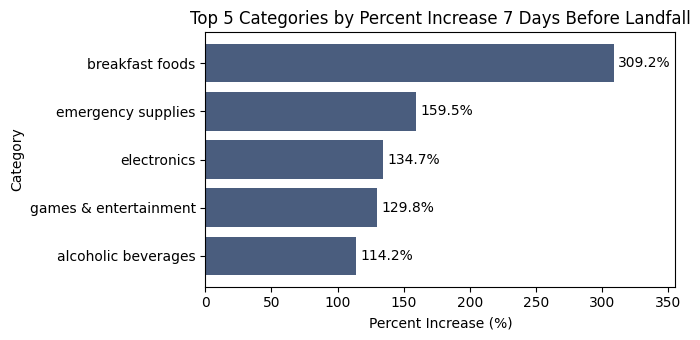

In [132]:
# Visualization
import matplotlib.pyplot as plot

s = top5["percent_increase"].sort_values()
fig, ax = plot.subplots(figsize=(7, 3.5))
ax.margins(x=0.15)
cat_graph = ax.barh(s.index, s.values, color='#4a5d7e')
ax.bar_label(cat_graph, fmt='%.1f%%', padding=3)
ax.set_title("Top 5 Categories by Percent Increase 7 Days Before Landfall")
ax.set_xlabel("Percent Increase (%)")
ax.set_ylabel("Category")
plot.tight_layout()
plot.show()

Our analysis displays the top five categories by percent increase in the surge period. The surge period refers to the seven days before landfall. We use the seven days before that period as our baseline. We calculated landfall as 2024-09-26 using wind speed as the determining metric. We utilized wind speed as the proxy for landfall since it typically coincides with the storm's approach. The landfall day is not included in the time periods themselves, since it may skew the results. Each category showed an increase; however, the five with the highest percentages were: 'breakfast foods' (309.2%), 'emergency supplies' (159.5%), 'electronics' (134.7%), 'games & entertainment' (129.8%), and 'alcoholic beverages' (114.2%). Our suggestion would be that Walmart keeps these categories stocked in anticipation of a storm, knowing that they see the greatest increase in purchases.

### Question 2: The Pop-Tarts Effect (SKU Consolidation)

> *After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?*

In [133]:
import numpy as np

poptart_regex = r"pop[\s\-_]*tart"

all_poptarts = (
    df_product["product_name"].str.contains(poptart_regex, regex=True) |
    df_product["subcategory"].str.contains(poptart_regex, regex=True) |
    df_product_original["product_name"].str.contains(poptart_regex, regex=True)
)

sku_map = df_product.loc[all_poptarts, ["sku", "product_name", "package_size"]].copy()
sku_map["raw_product_name"] = df_product_original.loc[all_poptarts, "product_name"]
sku_map["standard_name"] = "poptarts"

df2 = df_transaction.copy()
df2["raw_sku"] = df_transaction_original["sku"].reindex(df2.index)
df2["raw_product_name"] = df_transaction_original["product_name"].reindex(df2.index)

df2 = df2.dropna(subset=["timestamp"]).copy()
df2["date"] = df2["timestamp"].dt.normalize()
df2["revenue"] = df2["quantity"]*df2["unit_price"]

x = df2[
    df2["raw_product_name"].str.contains(poptart_regex, regex=True)
    & ~df2["sku"].isin(sku_map["sku"])
]

if len(x):
  new_rows = pd.DataFrame({"sku": x["sku"].dropna().unique()})
  new_rows["standard_name"] = "poptarts"
  sku_map = pd.concat([sku_map, new_rows], ignore_index=True)

sku_map = sku_map.drop_duplicates(subset="sku")
print(sku_map)

df2["poptart"] = df2["sku"].isin(sku_map["sku"])
df2["clean"] = df2["sku"].map(sku_map.set_index("sku")["standard_name"])
df2["fragmented"] = np.where(df2["poptart"], df2["raw_sku"].astype(str), df2["product_name"])

             sku         product_name package_size      raw_product_name  \
0          pt-12  strawberry pop-tart       4-pack  pop-tarts strawberry   
2  poptart-straw  strawberry pop-tart       6-pack  Pop-Tarts Strawberry   

  standard_name  
0      poptarts  
2      poptarts  


In [134]:
pop = df2[df2["poptart"]]

time = pd.date_range(df2["date"].min(), df2["date"].max(), freq="D")
days = len(time)

fragmented_sales = (
    pop.groupby(["date", "fragmented"])["quantity"].sum()
    .unstack("fragmented")
    .reindex(time)
    .fillna(0)
)

consol_sales = (
    pop.groupby("date")["quantity"].sum()
    .reindex(time)
    .fillna(0)
)

In [135]:
frag_summary = pd.DataFrame({
    "total_units": fragmented_sales.sum(),
    "avg_daily_units": fragmented_sales.mean(),
})
frag_summary["share_of_total_%"] = frag_summary["total_units"] / frag_summary["total_units"].sum() * 100

consol_summary = pd.Series({
    "total_units": consol_sales.sum(),
    "avg_daily_units": consol_sales.mean(),
})

print("\nFragmented Summary (per SKU variant):")
print(frag_summary.round(2))
print("\nConsolidated Summary:")
print(consol_summary.round(2))


Fragmented Summary (per SKU variant):
               total_units  avg_daily_units  share_of_total_%
fragmented                                                   
POPTART-STRAW         1245            41.50             24.78
PT-12                 1336            44.53             26.59
PT_STRAWBERRY         1238            41.27             24.64
SKU#459812            1206            40.20             24.00

Consolidated Summary:
total_units        5025.0
avg_daily_units     167.5
dtype: float64


In [136]:
# Fragmented product ranking
f_rank = df2.groupby("fragmented").agg(total_units=("quantity", "sum"), total_revenue=("revenue", "sum"))
f_rank["avg_daily_units"] = f_rank["total_units"] / days
f_rank["unit_rank"] = f_rank["total_units"].rank(ascending=False, method="min").astype(int)
f_rank["revenue_rank"] = f_rank["total_revenue"].rank(ascending=False, method="min").astype(int)
rank_frag = f_rank.sort_values("total_units", ascending=False)

# Consolidated product ranking
c_rank = df2.groupby("clean").agg(total_units=("quantity", "sum"), total_revenue=("revenue", "sum"))
c_rank["avg_daily_units"] = c_rank["total_units"] / days
c_rank["unit_rank"] = c_rank["total_units"].rank(ascending=False, method="min").astype(int)
c_rank["revenue_rank"] = c_rank["total_revenue"].rank(ascending=False, method="min").astype(int)
rank_consol = c_rank.sort_values("total_units", ascending=False)

# Output
frag_poptart_ranks = rank_frag.loc[rank_frag.index.isin(fragmented_sales.columns)]
print(f"\nProducts in fragmented view: {len(rank_frag)} | in consolidated view: {len(rank_consol)}")
print("\nPop-Tart variants in the fragmented ranking:")
print(frag_poptart_ranks)
print("\nPop-Tarts in the consolidated ranking:")
print(rank_consol.loc[["poptarts"]])



Products in fragmented view: 27 | in consolidated view: 1

Pop-Tart variants in the fragmented ranking:
               total_units  total_revenue  avg_daily_units  unit_rank  \
fragmented                                                              
PT-12                 1336        4653.40        44.533333         16   
POPTART-STRAW         1245        4345.18        41.500000         17   
PT_STRAWBERRY         1238        4319.74        41.266667         18   
SKU#459812            1206        4208.61        40.200000         19   

               revenue_rank  
fragmented                   
PT-12                    24  
POPTART-STRAW            25  
PT_STRAWBERRY            26  
SKU#459812               27  

Pop-Tarts in the consolidated ranking:
          total_units  total_revenue  avg_daily_units  unit_rank  revenue_rank
clean                                                                         
poptarts         5025       17526.93            167.5          1             1

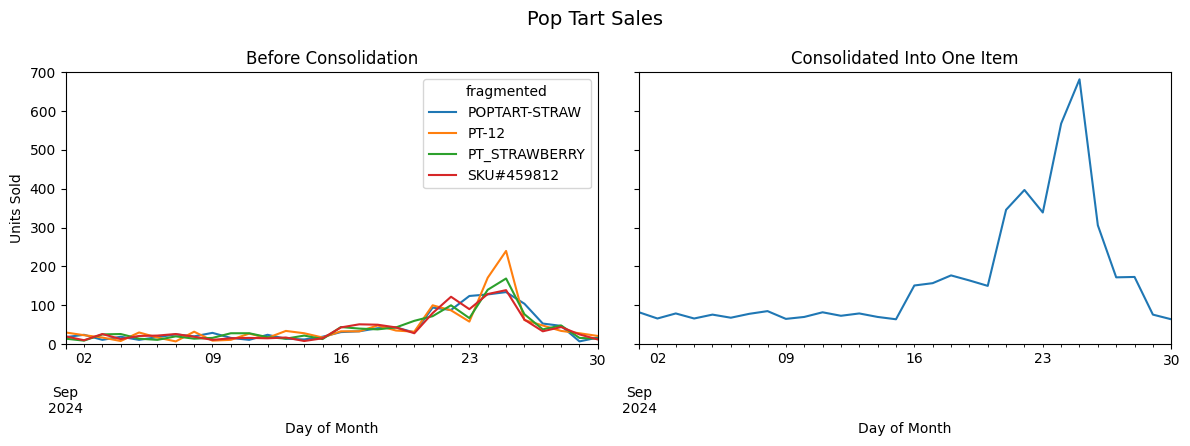

Fragmented total: 5025
Consolidated total: 5025


In [137]:
# Visualization
import matplotlib.pyplot as plot
fig, (f1, f2) = plot.subplots(1, 2, figsize=(12, 4.5), sharey=True)
fig.suptitle("Pop Tart Sales", fontsize=14)

# Fragmented
fragmented_sales.plot(ax=f1, title= "Before Consolidation")
f1.set_xlabel("Day of Month")
f1.set_ylabel("Units Sold")
f1.set_ylim(0, 700)

# Consolidated
consol_sales.plot(ax=f2, title="Consolidated Into One Item")
f2.set_xlabel("Day of Month")
f2.set_ylabel("Units Sold")
f2.set_ylabel("Units Sold")
f2.set_ylim(0, 700)

plot.tight_layout()
plot.show()

print("Fragmented total:", fragmented_sales.sum().sum())
print("Consolidated total:", consol_sales.sum())

This section addresses the issue of data fragmentation in the Pop-Tart product. It appears under four different SKU codes, causing the data to inaccurately reflect its sales. The code builds a SKU map to combine "pop tart", "pop-tart", "pop_tart", and "poptart" into one item under the moniker "poptarts." Each of the four variants had relatively low individual sales, but together totaled 5,025 units.
The four variants rank among the lowest in revenue, despite ranking 16th through 19th in units sold. However, after consolidation, "poptarts" ranks highest in both revenue and units sold. The analysis demonstrates the importance of SKU standardization before ranking products. While each variant appears to be a relatively low performer on its own, together they generate approximately $17,500 in revenue. Without consolidation, Walmart may mistakenly classify these products as low performers and reduce their inventory. By addressing this fragmentation, Walmart can recognize the product's strong demand and prioritize keeping it in stock in anticipation of a storm.

### Question 3: Weather Correlation Analysis (Weather vs. Sales)

> *Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?*

In [138]:
sales = df.dropna(subset=["timestamp", "category", "store_id"]).copy()
sales = sales[sales["store_id"].isin(weather_all["store_id"].unique())]
sales["date"] = sales["timestamp"].dt.normalize()

daily_cat = sales.groupby(["date", "category"])["quantity"].sum().unstack("category")

daily_weather = weather_all.groupby("date")[["windspeed_10m_max", "precipitation_sum", "pressure_msl_mean"]].mean()
daily_cat = daily_cat.reindex(daily_weather.index).fillna(0)


# Peak sales, peak weather conditions
wind_peak = daily_weather["windspeed_10m_max"].idxmax()
rain_peak = daily_weather["precipitation_sum"].idxmax()
pressure_peak = daily_weather["pressure_msl_mean"].idxmax()

timing = pd.DataFrame({"peak_sales_date": daily_cat.idxmax()})
timing["days_before_wind_peak"] = (wind_peak - timing["peak_sales_date"]).dt.days
timing["days_before_rain_peak"] = (rain_peak - timing["peak_sales_date"]).dt.days

print(timing)

                      peak_sales_date  days_before_wind_peak  \
category                                                       
alcoholic beverages        2024-09-25                      1   
baby products              2024-09-24                      2   
breakfast foods            2024-09-25                      1   
electronics                2024-09-24                      2   
emergency supplies         2024-09-24                      2   
games & entertainment      2024-09-25                      1   
groceries                  2024-09-25                      1   
health & wellness          2024-09-24                      2   
household essentials       2024-09-25                      1   
snacks                     2024-09-25                      1   

                       days_before_rain_peak  
category                                      
alcoholic beverages                      -17  
baby products                            -16  
breakfast foods                          -1

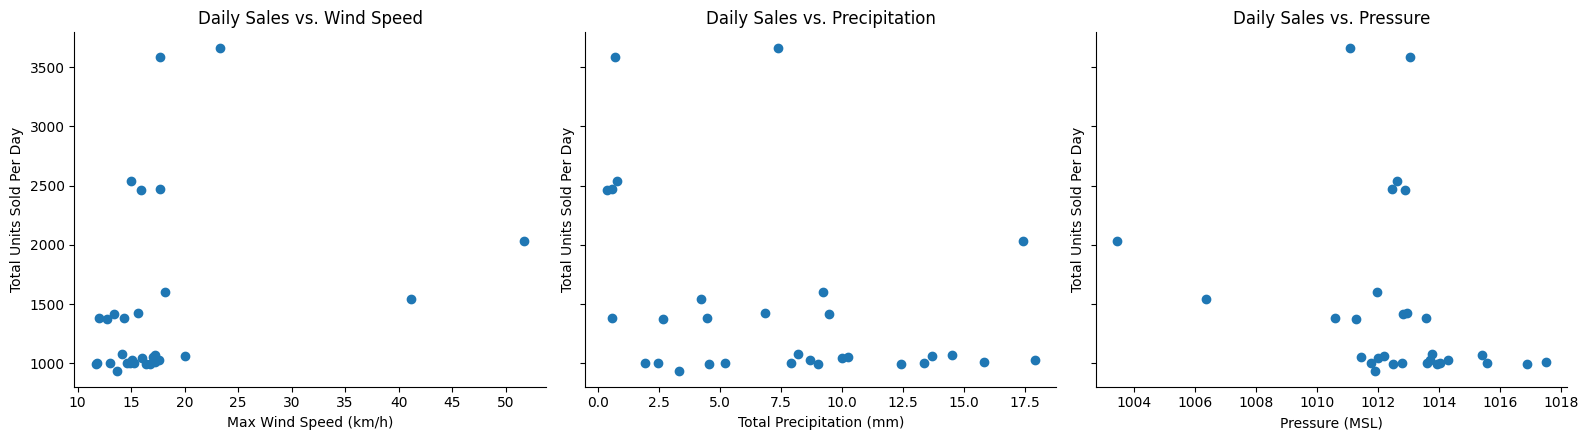

Wind Correlation Coefficient:  0.26758206225880127
Rain Correlation Coefficient:  -0.36544224444842716
Pressure Correlation Coefficient:  -0.2834439849316367


In [141]:
# Visualization
import matplotlib.pyplot as plot
daily_total = daily_cat.sum(axis=1)

fig, (ax1, ax2, ax3) = plot.subplots(1, 3, figsize=(16, 4.5), sharey=True)

# Sales vs. wind
ax1.scatter(daily_weather["windspeed_10m_max"], daily_total)
ax1.set_title("Daily Sales vs. Wind Speed")
ax1.set_xlabel("Max Wind Speed (km/h)")
ax1.set_ylabel("Total Units Sold Per Day")

# Sales vs. rain
ax2.scatter(daily_weather["precipitation_sum"], daily_total)
ax2.set_title("Daily Sales vs. Precipitation")
ax2.set_xlabel("Total Precipitation (mm)")
ax2.set_ylabel("Total Units Sold Per Day")

# Sales vs. pressire
ax3.scatter(daily_weather["pressure_msl_mean"], daily_total)
ax3.set_title("Daily Sales vs. Pressure")
ax3.set_xlabel("Pressure (MSL)")
ax3.set_ylabel("Total Units Sold Per Day")

# Plot
for ax in (ax1, ax2, ax3):
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

plot.tight_layout()
plot.show()

# Correlation Coefficients
corr_wind = daily_total.corr(daily_weather["windspeed_10m_max"])
corr_rain = daily_total.corr(daily_weather["precipitation_sum"])
corr_pressure = daily_total.corr(daily_weather["pressure_msl_mean"])
print("Wind Correlation Coefficient: ", corr_wind)
print("Rain Correlation Coefficient: ", corr_rain)
print("Pressure Correlation Coefficient: ", corr_pressure)

Our analysis shows that sales across all ten categories peak in the two-day window before landfall. The wine and rain corerlation coefficent is low. The wind speed correlation coefficient is 0.268, indicating a weak positive relationship between wind speed and daily sales. Similarly, the precipitation correlation coefficient is -0.365, indicating a weak negative relationship between precipitation and daily sales. Despite the relativelt weak correlations displayed in the scatterplots, the surge window before landfall remains evident. The latter may suggest that shoppers respond more to the anticipation and progression of the storm rather than the individual conditions on a given day. Additionally, the two-day purchasing surge suggests customer's typically stock up before the storm reaches its most severe condition.

### Question 4: Store-Level Geographic Patterns

> *Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.*

In [ ]:
# Landfall latitude and longitude (Perry, Florida)
lat = 30.1
longit = -83.6

stores = df_store[["store_id", "city", "latitude", "longitude"]].copy()
stores["distance"] = ((stores["latitude"] - lat)**2 + (stores["longitude"] - longit)**2)**0.5

df3 = df.dropna(subset=["timestamp", "store_id"]).copy()
df3["date"] = df3["timestamp"].dt.normalize()
df3["revenue"] = df3["quantity"] * df3["unit_price"]

days = pd.date_range(baseline_start, landfall - pd.Timedelta(days=1))
daily = df3.groupby(["date", "store_id"])["revenue"].sum().unstack().reindex(days).fillna(0)

base = daily[daily.index < surge_start].mean()
surgedays = daily[daily.index >= surge_start]

df4 = pd.DataFrame({
    "percent_increase": (surgedays.mean() - base) / base * 100,
    "peak_days_before": (landfall - surgedays.idxmax()).dt.days
}).reset_index().merge(stores, on="store_id").sort_values("distance", ascending=False)

outliers = (df4["percent_increase"] - df4["percent_increase"].mean()) / df4["percent_increase"].std()
df4["outlier"] = outliers.abs() > 2

for x in df4.index:
  if df4.loc[x, "outlier"] == True:
    print(df4.loc[x, "store_id"])

In [ ]:
# Visualization
fig, ax = plot.subplots(figsize=(7, 4))
rev_graph = ax.barh(df4["store_id"], df4["percent_increase"], color='#4a5d7e')
ax.bar_label(rev_graph, fmt='%.1f%%', padding=3)
ax.margins(x=0.15)
ax.set_title("Percent Increase in Average Daily Revenue by Store\n(Ordered by Distance From Landfall)")
ax.invert_yaxis()
ax.set_xlabel("Percent Increase in Average Daily Revenue (%)")
ax.set_ylabel("Store \n(Furthest to Closest from Landfall, Top to Bottom)")
plot.tight_layout()
plot.show()

This section analyzes the relationship between proximity to landfall and sales during the pre-storm periods. For each store, the code compares the average daily revenue in the surge window (7 days before landfall) and the baseline period (14 days before landfall), using Perry, Florida, as the landfall location. The bar chart is ordered from closest to furthest, from top to bottom. There does not appear to be a direct relationship between the distance from landfall and the magnitude of the sales surge. All stores show relatively similar increases in average daily revenue, ranging from 94.6% to 129%. The only notable outlier is fl-239, which experienced a 94.6% increase, approximately 22.38 percentage points below the average increase of 116.98%. These findings suggest that stores across Florida experience relatively consistent purchasing surges, regardless of proximity to landfall. Walmart should anticipate an increase in demand across all Florida locations.

### Question 5: Signal vs. Artifact — The Board Games Investigation

> *The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?*

In [ ]:
# Visualization

import matplotlib.pyplot as plt

# Compare percentage increases from both datasets
plt.figure(figsize=(8, 5))

plt.bar(
    ["SQL Sales Summary", "Transactions"],
    q5_results["Percent Increase"]
)

plt.title("Entertainment Revenue Increase During Surge Period")
plt.ylabel("Increase Compared to Baseline (%)")
plt.xlabel("Data Source")

# Add percentage labels above bars
for i, value in enumerate(q5_results["Percent Increase"]):
    plt.text(i, value + 2, f"{value:.1f}%", ha="center")

plt.ylim(0, 200)
plt.tight_layout()
plt.show()

Our analysis suggests that the increase in Entertainment sales is a genuine sales signal, but the exact size of the increase is uncertain due to data-quality issues. We compared the SQLite daily sales summary with the cleaned transaction dataset. Using September 1–20 as the baseline and September 21–26 as the surge period, the SQL data showed a 160.26% increase in average daily revenue, while the transaction data showed a 167.60% increase. Both datasets showed similar trends, with sales peaking around September 24–25.

However, we identified several possible data artifacts. Monopoly and playing cards appeared under multiple SKU identifiers, and the transaction SKU `BG-MONO` required a provisional mapping to `GAME-MONO` in the inventory database. Only 598 of 2,538 board-game-related transactions matched an exact inventory record using store, date, and SKU. We also found four Entertainment records with negative revenue in the SQL summary. These issues suggest that reporting differences and incomplete inventory coverage could affect our interpretation of sales.

Our inventory analysis also showed some signs of low stock. For example, GAME-MONO was at or below its reorder point in 27.17% of its recorded inventory observations. However, we did not find any recorded zero-stock values for the four entertainment-related SKUs. This suggests that inventory availability may have been a concern, but we cannot confirm actual stockouts from these records alone.

**Our Recommendation:** Walmart should consider a modest, targeted increase in board-game inventory before future hurricanes rather than a large increase based solely on the reported 250% surge. The consistent sales pattern across both datasets supports preparing for higher demand, but Walmart should first improve SKU standardization and inventory reporting. Additional historical sales and inventory data would help determine the appropriate stocking levels. Since the Entertainment category includes both Monopoly and playing cards, the overall category increase does not necessarily mean Monopoly sales increased by the same percentage.

## **Reflection Questions**

### Question 1: Data Quality Impact

> *Describe a specific data quality issue you encountered in the supplied data. How did your cleaning decision change the outcome of your analysis? What would have happened if you had not caught it?*

One data quality issue we encountered was the inconsistent product naming within the datasets. For example, the same product could be "first aid kit" and "first-aid kit" or "pop-tarts strawberry" and "strawberry pop-tart". These variants are the same product. The naming conventions and formatting differences cause the products to be treated as separate items in the analysis.

To address this discrepancy, we standardized the product names. This allows us to see that the variations are referring to the same item by grouping them. By cleaning the unstandardized values, we created a better representation of the product-level sales trends, as shown by the fragmented sales visualization compared with the consolidated sales visualization. Standardizing the product names makes it easier to recognize patterns that were unclear or would have been dispersed across multiple product labels if we did not clean the data.

If we did not resolve this issue, the same product's sales could have been spread across multiple names. The latter could cause an individual product trend to look smaller or less consistent, thus causing our analysis to overlook a meaningful trend/pattern. By standardizing the product names, we improved data consistency and ensured the accuracy of our analysis.

### Question 2: ETL Trade-offs

> *You made choices about how to standardize SKUs, handle missing timestamps, and join weather data. Pick one decision and explain: what alternative approach could you have taken, and how might it have changed your results?*

Handling Missing Timestamps:

In the walmart_transactions.csv file, there were originally 886 missing timestamp values. The original data type of the timestamp column was object. To make downstream analysis easier, we decided to convert the column into datetime objects.

Initially, we used pd.to_datetime(df[column_name], errors='coerce'). However, errors='coerce' tells pandas to convert valid timestamp strings into datetime objects and convert both missing values and unparseable timestamp values into NaT. This last case is what caused our missing value count to increase from 884 to 23,028. This indicated that many timestamp values that were not originally missing could not be interpreted using pandas' default datetime parsing behavior. In other words, many of the original timestamp values may not be compatible with pandas' datetime parsing rules.

To address this issue, we included the format='mixed' parameter. This allows pandas to infer the format of each timestamp individually, which is useful because our dataset contains multiple timestamp formats. After applying this approach, we were able to successfully parse the existing timestamp values while preserving the original missing values as NaT.

Additionally, we decided to keep the missing timestamps rather than fill them with estimated or dummy values because we did not have enough information to determine what the original dates and times should have been.

One alternative decision would have been to keep the original errors='coerce' implementation without specifying format='mixed'. However, this would have resulted in 23,028 missing timestamps out of 25,562 transactions, leaving only 2,534 transactions with usable timestamps. This would have significantly reduced the amount of data available for time-based analysis, potentially making our conclusions about transaction trends less reliable.

Another alternative decision would have been to fill the missing timestamps with dummy or estimated values. Although this would have reduced the number of missing values, it could have introduced inaccurate information and distorted our analysis of transaction patterns over time. Ultimately, we decided that preserving missing values was better than introducing information that we could not verify.

### Question 3: Pipeline Trust

> *The Walmart CDO argued that the biggest risk is not the model — it is the pipeline. Based on your experience in this project, do you agree or disagree? What was the most fragile part of your data pipeline?*

I agree with the Walmart CDO that the biggest risk is the data pipeline rather than the model itself. When working on the Weather API portion of our project, I realized how much our results depend on having reliable and correctly matched data.

One of the biggest challenges we encountered was when the Open-Meteo API became overloaded and returned a 503 error, preventing us from retrieving the weather data. We also had missing store coordinates and transaction timestamps, which meant that not every sales record could be matched with weather information. Another concern was that the original sales timestamps did not specify a timezone, so we had to document our assumption about using Florida local time. I think the most fragile part of our pipeline was integrating the weather data with the sales transactions because even a small issue with dates or store locations could affect our analysis.

This experience taught us that checking data quality and validating joins are just as important as the analysis itself, since unreliable data can lead to misleading conclusions.

### Question 4: Business vs. Data

> *For Question 5 (board games), your team had to make a recommendation with imperfect data. How did you weigh statistical evidence against business risk? Would you have decided differently with more time or more data?*

For Question 5, I tried to balance what our data showed with the risks Walmart could face by ordering too much inventory. Both our SQL database and transaction data showed an increase in Entertainment sales of about 160–168%, which suggested that demand was increasing. However, we also found issues with inconsistent SKU names, missing inventory matches, and differences in reported sales totals. Because of these limitations, I wouldn't recommend that Walmart significantly increase its board-game inventory based only on the reported 250% surge. Instead, I would recommend a smaller, targeted increase to avoid having too much unsold inventory after the storm. If we had more time or data, I would want to compare sales across multiple hurricane seasons and look at more complete inventory records. This would help us determine whether the increase happens consistently and make a more confident recommendation.

### Question Five: Team Collaboration

> *How did your team divide the work? What would you do differently if you had another week? What was the most valuable skill each team member contributed?*

We divided the work into data cleaning, API calls, analytical questions/ visualizations, and each person completed a reflection question based on their assignment. If we had another week, we would look further into the data cleaning process to ensure each step was done correctly, as well as further into the analysis. By looking further into the analysis, we can ensure the understanding of the trends vs. what is noise. In addition, we could create more in-depth visualizations to better model the trends and to attempt to make them easier to understand for viewers with less context. For data cleaning and the API call, the members primarily used their Python knowledge and SQL (inventory & sales data). For the analytical questions and visuals, they used Python and their knowledge of data visualization.